<a href="https://colab.research.google.com/github/Carmen10-171/07MIAR_Redes-Neuronales/blob/main/07miar_proyecto_programacion_v2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 07MIAR - Redes Neuronales y Deep Learning: Proyecto de programación "*Deep Vision in classification tasks*"


## Raúl Medina
## Juan José
## Alfredo
## Mª Camen Copé Soler

Presentación
Grupo 1 Proyecto de programación 1

https://github.com/07MIAR-grupo1-plantseedlings/Proyecto-CNN-PlantSeedlings

## Enunciado

En esta actividad, el alumno debe **evaluar y comparar dos estrategias** para la **clasificación de imágenes** empleando el **dataset asignado**. El/La alumnx deberá resolver el reto proponiendo una solución válida **basada en aprendizaje profundo**, más concretamente en redes neuronales convolucionales (**CNNs**). Será indispensable que la solución propuesta siga el **pipeline visto en clase** para resolver este tipo de tareas de inteligencia artificial:

1.   **Carga** del conjunto de datos
2.   **Inspección** del conjunto de datos
3.   **Acondicionamiento** del conjunto de datos
4.   Desarrollo de la **arquitectura** de red neuronal y **entrenamiento** de la solución
5.   **Monitorización** del proceso de **entrenamiento** para la toma de decisiones
6.   **Evaluación** del modelo predictivo y planteamiento de la siguiente prueba experimental

### Estrategia 1: Entrenar desde cero o *from scratch*

La primera estrategia a comparar será una **red neuronal profunda** que el **alumno debe diseñar, entrenar y optimizar**. Se debe **justificar empíricamente** las decisiones que llevaron a la selección de la **arquitectura e hiperparámetros final**. Se espera que el alumno utilice todas las **técnicas de regularización** mostradas en clase de forma justificada para la mejora del rendimiento de la red neuronal (*weight regularization*, *dropout*, *batch normalization*, *data augmentation*, etc.).

### Estrategia 2: Red pre-entrenada

La segunda estrategia a comparar debe incluir la utilización de una **red preentrenada** con el dataset ImageNet, llevando a cabo tareas de ***transfer learning*** y ***fine-tuning*** para resolver la tarea de clasificación asignada. Deben **compararse al menos dos tipos de arquitecturas** (VGGs, ResNet50, Xception, InceptionV3, InceptionResNetV2, MobileNetV2, DenseNet, ResNet) y se debe **seleccionar la que mayor precisión proporcione** (información sobre las arquitecturas disponibles en https://keras.io/applications/). Se espera que el/la alumnx utilice todas las **técnicas de regularización** mostradas en clase de forma justificada para la mejora del rendimiento de la red neuronal (*weight regularization*, *dropout*, *batch normalization*, *data augmentation*, etc.).

## Normas a seguir

- Será **indispensable** realizar el **trabajo por parejas**. Dichas parejas de alumnxs se generarán **de manera automática** teniendo en cuenta el pais de residencia con el objetivo de facilitar el trabajo en equipo.  
- Se debe entregar un **ÚNICO FICHERO PDF POR ALUMNO** que incluya las instrucciones presentes en el Colab Noteboook y su **EJECUCIÓN!!!**. Debe aparecer todo el proceso llevado a cabo en cada estrategia (i.e. carga de datos, inspección de datos, acondicionamiento, proceso de entrenamiento y proceso de validación del modelo).
- **La memoria del trabajo** (el fichero PDF mencionado en el punto anterior) deberá **subirla cada integrante del grupo** (aunque se trate de un documento idéntico) a la actividad que se habilitará **en CampusVIU**.
- Se recomienda trabajar respecto a un directorio base (**BASE_FOLDER**) para facilitar el trabajo en equipo. En este notebook se incluye un ejemplo de cómo almacenar/cargar datos utilizando un directorio base.
- Las **redes propuestas** deben estar **entrenadas** (y **EVIDENCIAR este proceso en el documento PDF**). La entrega de una **red sin entrenar** supondrá **perdida de puntos**.
- Si se desea **evidenciar alguna métrica** del proceso de entrenamiento (precisión, pérdida, etc.), estas deben ser generadas.
- Todos los **gráficos** que se deseen mostrar deberán **generarse en el Colab Notebook** para que tras la conversión aparezcan en el documento PDF.

## *Tips* para realizar la actividad con éxito
- Los **datos** se cargarán directamente **desde** la plataforma **Kaggle** mediante su API (https://github.com/Kaggle/kaggle-api). En este Notebook se incluye un ejemplo de como hacerlo. Se recomienda generar una función que aborde esta tarea.
- El **documento PDF a entregar** como solución de la actividad se debe **generar automáticamente desde el fichero ".ipynb"**. En este Notebook se incluye un ejemplo de como hacerlo.
- **Generar secciones y subsecciones en el Colab Notebook** supondrá que el documento **PDF generado** queda totalmente **ordenado** facilitando la evaluación al docente.
- Se recomienda encarecidamente **incluir comentarios concisos pero aclaratorios**.
- Es muy recomendable crear una **última sección** de texto en el Colab Notebook en la que se discutan los diferentes modelos obtenidos y se extraigan las conclusiones pertinentes.

## Criterios de evaluación

- **Seguimiento** de las **normas establecidas** en la actividad (detalladas anteriormente).
- Creación de una **solución que resuelva la tarea de clasificación**, i.e. que las figuras de mérito empleadas para medir la bondad del modelo predictivo evidencien un *performance* superior al rendimiento estocástico.
- **Claridad** en la creación de la solución, en las justificaciones sobre la toma de decisiones llevada a cabo así como en las comparativas y conclusiones finales.
- **Efectividad** al presentar las comparaciones entre métricas de evaluación de ambas estrategias.
- **Demostración** de la utilización de **técnicas de regularización** para mejorar el rendimiento de los modelos.

## 1. Carga de datos

En primer lugar se debe generar un API de Kaggle personal, para ello:
* 1. Registrarse en  https://www.kaggle.com
* 2. Ir a 'Account tab' de tu perfil y seleccionar 'Create API Token'
* 3. Almacenar en tu ordenador local el fichero kaggle.json

Siguiendo las indicaciones de la asignatura, se revisó el procedimiento de descarga mediante la API oficial de Kaggle. No obstante, para evitar descargas repetidas y optimizar el entorno de desarrollo, los experimentos se realizaron sobre una copia local previamente descargada del dataset Plant Seedlings Classification.

In [ ]:
import os

BASE_FOLDER = r"C:\Users\ccope\OneDrive\Documents\plant-seedlings-classification"
#BASE_FOLDER = "."

train_path = os.path.join(BASE_FOLDER, "train")
test_path  = os.path.join(BASE_FOLDER, "test")

print(os.listdir(BASE_FOLDER))



['sample_submission.csv', 'test', 'train']


In [ ]:
import tensorflow as tf

IMG_SIZE = (224,224)

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_path,
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=32
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    train_path,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=32
)

Found 4750 files belonging to 12 classes.
Using 3800 files for training.
Found 4750 files belonging to 12 classes.
Using 950 files for validation.


# 2. Inspección del Dataset
Antes de entrenar cualquier modelo es necesario conocer la estructura y características del conjunto de datos. En esta sección se analiza el número de clases, la cantidad de imágenes disponibles y algunos ejemplos visuales de cada categoría.

In [ ]:
#Número de imágenes por clase
import os

print("Número de clases:", len(os.listdir(train_path)))

print("\nClases disponibles:\n")

for clase in sorted(os.listdir(train_path)):
    print(clase)

Número de clases: 12

Clases disponibles:

Black-grass
Charlock
Cleavers
Common Chickweed
Common wheat
Fat Hen
Loose Silky-bent
Maize
Scentless Mayweed
Shepherds Purse
Small-flowered Cranesbill
Sugar beet


In [ ]:
# Número de imágenes por clase
import pandas as pd

class_counts = {}

for clase in os.listdir(train_path):

    ruta_clase = os.path.join(train_path, clase)

    if os.path.isdir(ruta_clase):

        class_counts[clase] = len(os.listdir(ruta_clase))

df_counts = pd.DataFrame(
    class_counts.items(),
    columns=["Clase", "Numero_imagenes"]
)

df_counts = df_counts.sort_values(
    by="Numero_imagenes",
    ascending=False
)

df_counts

,Clase,Numero_imagenes
6,Loose Silky-bent,654
3,Common Chickweed,611
8,Scentless Mayweed,516
10,Small-flowered Cranesbill,496
5,Fat Hen,475
1,Charlock,390
11,Sugar beet,385
2,Cleavers,287
0,Black-grass,263
9,Shepherds Purse,231


C:\Users\ccope\AppData\Local\Temp\ipykernel_38300\2304859433.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


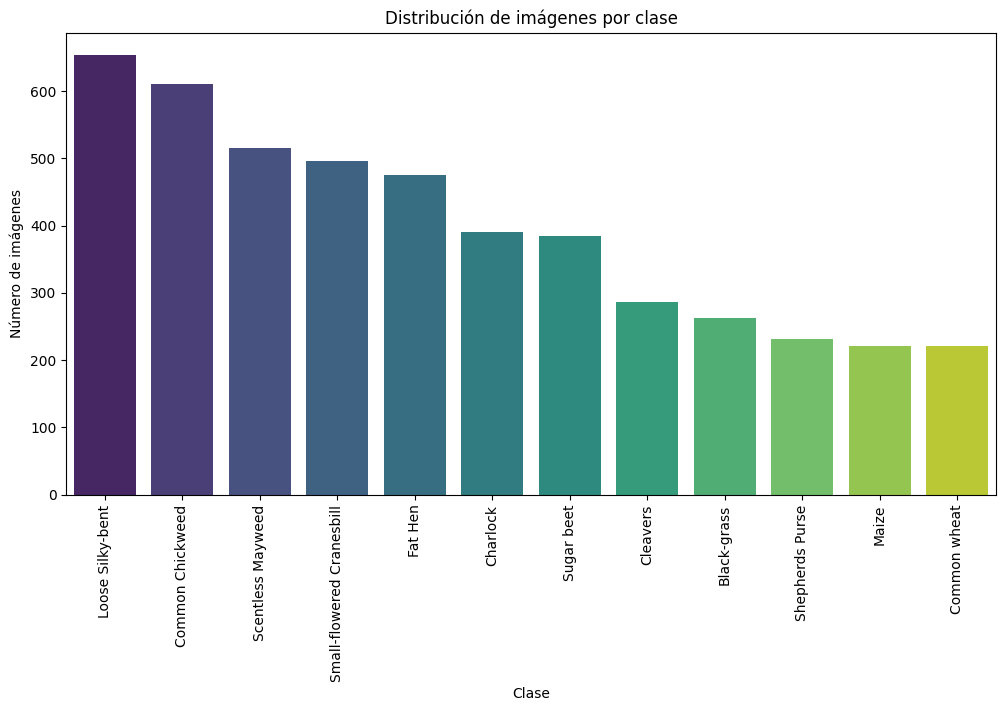

In [ ]:
# Distribución de clases
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12,6))

sns.barplot(
    data=df_counts,
    x="Clase",
    y="Numero_imagenes",
    palette="viridis"
)

plt.xticks(rotation=90)

plt.title("Distribución de imágenes por clase")

plt.xlabel("Clase")

plt.ylabel("Número de imágenes")

plt.show()

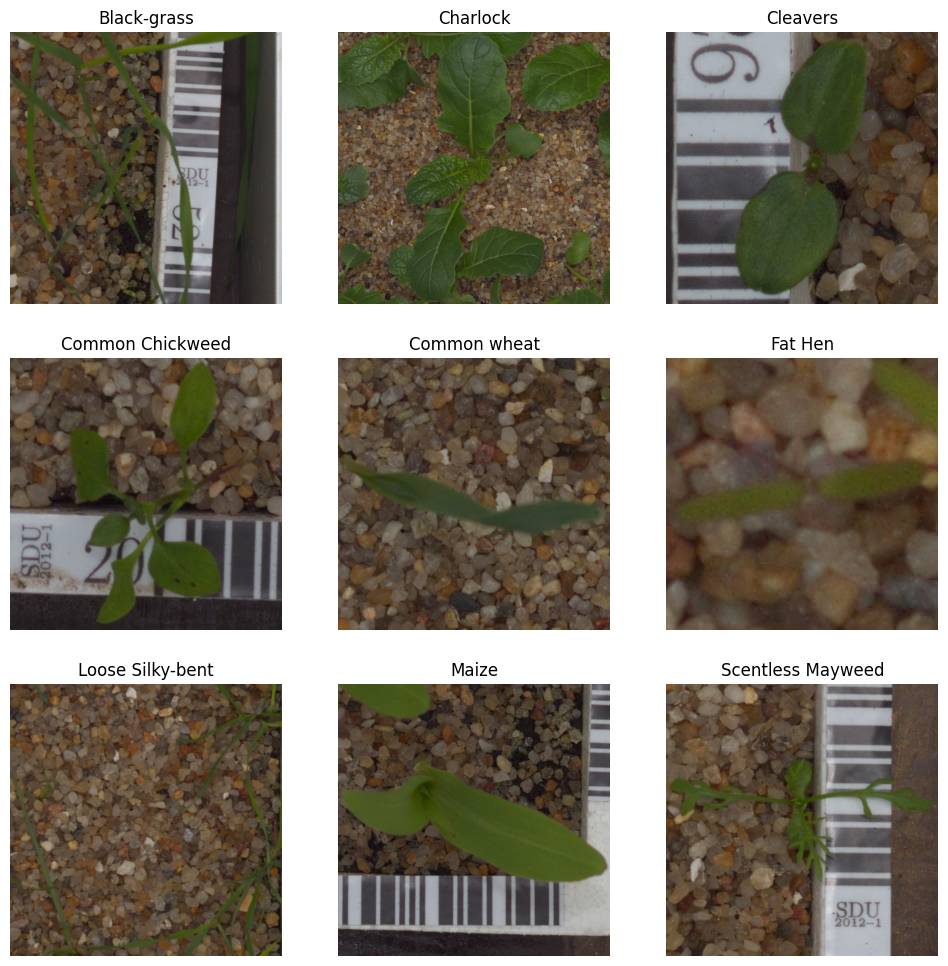

In [ ]:
# Visualización de imágenes
import cv2
import numpy as np

plt.figure(figsize=(12,12))

for i, clase in enumerate(sorted(os.listdir(train_path))[:9]):

    carpeta = os.path.join(train_path, clase)

    imagen = np.random.choice(os.listdir(carpeta))

    ruta = os.path.join(carpeta, imagen)

    img = cv2.imread(ruta)

    img = cv2.cvtColor(
        img,
        cv2.COLOR_BGR2RGB
    )

    plt.subplot(3,3,i+1)

    plt.imshow(img)

    plt.title(clase)

    plt.axis("off")

plt.show()


Conclusiones de la inspección
El conjunto de datos está compuesto por 12 especies vegetales diferentes organizadas en carpetas independientes. Tras el análisis exploratorio se observa que la estructura es adecuada para su carga automática mediante TensorFlow.

Las imágenes presentan diferentes orientaciones, tamaños y condiciones de captura, por lo que será necesario aplicar procesos de normalización y técnicas de aumento de datos (Data Augmentation) para mejorar la capacidad de generalización de los modelos.

Como siguiente paso experimental se procederá al acondicionamiento de los datos mediante redimensionado, normalización y construcción del pipeline de entrada para el entrenamiento de las redes neuronales.

# 3. Acondicionamiento del conjunto de datos

Tras la inspección inicial del dataset, es necesario preparar los datos para el entrenamiento de las redes neuronales convolucionales. Este proceso incluye la normalización de imágenes, la creación de los conjuntos de entrenamiento y validación, así como la optimización del pipeline de entrada de datos.

In [ ]:
# Redimensionado: Se selecciona un tamaño de entrada de 224×224 píxeles, ya que es compatible con la mayoría de
# las arquitecturas preentrenadas que se emplearán posteriormente.

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

In [ ]:
import tensorflow as tf

#Dataset de entrenamiento y validación
train_path = r"C:\Users\ccope\OneDrive\Documents\plant-seedlings-classification\train"

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_path,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    train_path,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

# Nombres de las clases

class_names = train_ds.class_names

print("Clases:")
print(class_names)
print(f"Número de clases: {len(class_names)}")


Found 4750 files belonging to 12 classes.
Using 3800 files for training.
Found 4750 files belonging to 12 classes.
Using 950 files for validation.
Clases:
['Black-grass', 'Charlock', 'Cleavers', 'Common Chickweed', 'Common wheat', 'Fat Hen', 'Loose Silky-bent', 'Maize', 'Scentless Mayweed', 'Shepherds Purse', 'Small-flowered Cranesbill', 'Sugar beet']
Número de clases: 12


In [ ]:
#Normalización
from tensorflow.keras import layers

normalization_layer = layers.Rescaling(1./255)

train_ds = train_ds.map(
    lambda x, y: (normalization_layer(x), y)
)

val_ds = val_ds.map(
    lambda x, y: (normalization_layer(x), y)
)

In [ ]:

#Comprobación de la normalización
for images, labels in train_ds.take(1):

    print("Valor mínimo:", images.numpy().min())
    print("Valor máximo:", images.numpy().max())




Valor mínimo: 0.0
Valor máximo: 1.0


In [ ]:
#Optimización del pipeline
AUTOTUNE = tf.data.AUTOTUNE

train_ds = (
    train_ds
    .cache()
    .shuffle(1000)
    .prefetch(AUTOTUNE)
)

val_ds = (
    val_ds
    .cache()
    .prefetch(AUTOTUNE)
)

In [ ]:
# verificacion de los lotes
for images, labels in train_ds.take(1):

    print("Forma imágenes:", images.shape)
    print("Forma etiquetas:", labels.shape)

Forma imágenes: (32, 224, 224, 3)
Forma etiquetas: (32,)


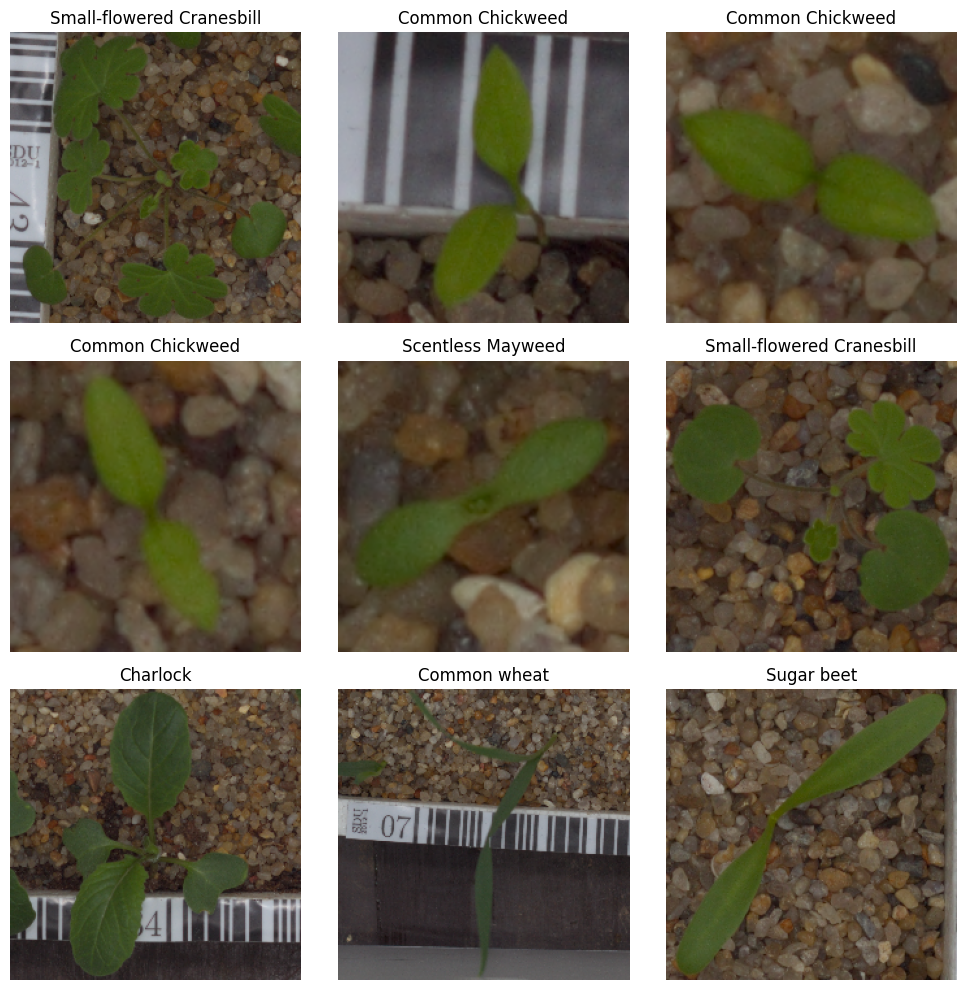

In [ ]:
#Visualización tras el preprocesado

import matplotlib.pyplot as plt

plt.figure(figsize=(10,10))

for images, labels in train_ds.take(1):

    for i in range(9):

        plt.subplot(3,3,i+1)

        plt.imshow(images[i])

        plt.title(class_names[labels[i]])

        plt.axis("off")

plt.tight_layout()
plt.show()


Las imágenes han sido redimensionadas a 224×224 píxeles y normalizadas al rango [0,1]. Asimismo, se ha realizado una partición del conjunto de datos en entrenamiento (80%) y validación (20%).

Finalmente, se ha optimizado el pipeline mediante técnicas de almacenamiento en caché, mezcla aleatoria y precarga automática de lotes, con el objetivo de reducir los tiempos de entrenamiento.

Una vez preparados los datos, se procede al desarrollo del primer modelo de referencia basado en una CNN entrenada desde cero.

## 4. Desarrollo de la arquitectura de red neuronal y entrenamiento de la solución

Experimento 1: CNN Base (Desarrollo de la arquitectura y entrenamiento).
Como punto de partida se construye una red neuronal convolucional sencilla que servirá como línea base para los experimentos posteriores.

La arquitectura está formada por tres bloques convolucionales seguidos de una etapa de clasificación densa. Su objetivo es establecer una referencia de rendimiento sobre la cual evaluar posteriormente el impacto de las técnicas de regularización.

Arquitectura
* Conv2D(32)
* Conv2D(64)
* Conv2D(128)
* Dense(128)
  
Entrenamiento
* history_base = model.fit(...)

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense
)

cnn_base = Sequential([

    Conv2D( 32, (3,3), activation='relu', padding='same', input_shape=(224,224,3)
    ),

    MaxPooling2D((2,2)),


    Conv2D( 64, (3,3), activation='relu', padding='same'),

    MaxPooling2D((2,2)),


    Conv2D(128, (3,3), activation='relu', padding='same'),

    MaxPooling2D((2,2)),


    Flatten(),

    Dense(128, activation='relu'),

    Dense( len(class_names), activation='softmax'
    )

])

cnn_base.summary()

C:\Users\ccope\miniconda3\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 100352)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    12,845,184 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 12)             │         1,548 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,939,980 (49.36 MB)

 Trainable params: 12,939,980 (49.36 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Compilación
from tensorflow.keras.optimizers import Adam

cnn_base.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [ ]:
#Callbacks
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau
)

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=3,
    verbose=1
)

In [ ]:
#Entrenamiento
history_base = cnn_base.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=[
        early_stop,
        reduce_lr
    ]
)

Epoch 1/5


C:\Users\ccope\miniconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


119/119 ━━━━━━━━━━━━━━━━━━━━ 258s 2s/step - accuracy: 0.2574 - loss: 2.2470 - val_accuracy: 0.4189 - val_loss: 1.6106 - learning_rate: 0.0010
Epoch 2/5
119/119 ━━━━━━━━━━━━━━━━━━━━ 295s 2s/step - accuracy: 0.5161 - loss: 1.4092 - val_accuracy: 0.5716 - val_loss: 1.3193 - learning_rate: 0.0010
Epoch 3/5
119/119 ━━━━━━━━━━━━━━━━━━━━ 214s 2s/step - accuracy: 0.6184 - loss: 1.1152 - val_accuracy: 0.6032 - val_loss: 1.2653 - learning_rate: 0.0010
Epoch 4/5
119/119 ━━━━━━━━━━━━━━━━━━━━ 198s 2s/step - accuracy: 0.6853 - loss: 0.9232 - val_accuracy: 0.6589 - val_loss: 1.1202 - learning_rate: 0.0010
Epoch 5/5
119/119 ━━━━━━━━━━━━━━━━━━━━ 186s 2s/step - accuracy: 0.7521 - loss: 0.7408 - val_accuracy: 0.6758 - val_loss: 1.1050 - learning_rate: 0.0010


## 5. Monitorización del proceso de entrenamiento para la toma de decisiones

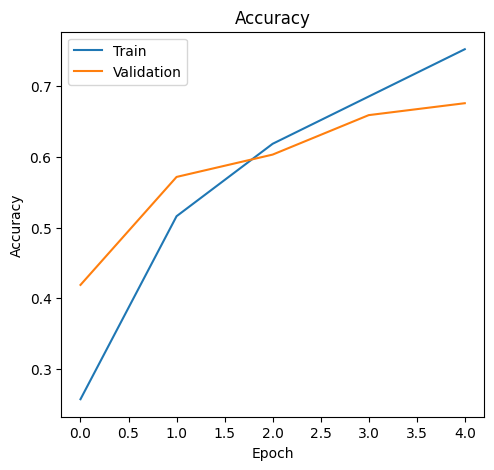

In [ ]:
#Accuracy
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))

plt.subplot(1,2,1)

plt.plot(
    history_base.history['accuracy'],
    label='Train'
)

plt.plot(
    history_base.history['val_accuracy'],
    label='Validation'
)

plt.title('Accuracy')

plt.xlabel('Epoch')

plt.ylabel('Accuracy')

plt.legend()

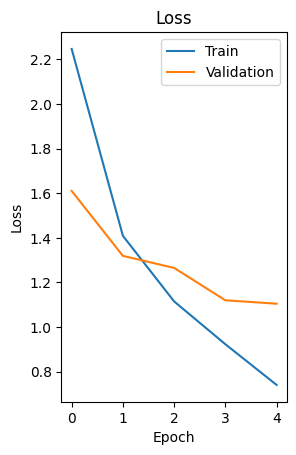

In [ ]:
# Loss
plt.subplot(1,2,2)

plt.plot(
    history_base.history['loss'],
    label='Train'
)

plt.plot(
    history_base.history['val_loss'],
    label='Validation'
)

plt.title('Loss')

plt.xlabel('Epoch')

plt.ylabel('Loss')

plt.legend()

plt.show()

Discusión de resultados
Las curvas de entrenamiento y validación permiten analizar la capacidad de aprendizaje del modelo.

En caso de observar una diferencia creciente entre la precisión de entrenamiento y validación, se considerará la existencia de sobreajuste, indicando que la red aprende adecuadamente las muestras de entrenamiento pero presenta dificultades para generalizar sobre datos no vistos.

# 6. Evaluación

In [ ]:
# Acurracy final
loss, accuracy = cnn_base.evaluate(
    val_ds
)

print(f"Loss: {loss:.4f}")
print(f"Accuracy: {accuracy:.4f}")

30/30 ━━━━━━━━━━━━━━━━━━━━ 8s 251ms/step - accuracy: 0.6758 - loss: 1.1050
Loss: 1.1050
Accuracy: 0.6758


In [ ]:
# Predicciones
import numpy as np

y_true = np.concatenate(
    [y for x, y in val_ds],
    axis=0
)

y_pred = np.argmax(
    cnn_base.predict(val_ds),
    axis=1
)

30/30 ━━━━━━━━━━━━━━━━━━━━ 8s 243ms/step


In [ ]:
#Classification Report
from sklearn.metrics import classification_report

print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names
    )
)

                           precision    recall  f1-score   support

              Black-grass       0.50      0.09      0.16        53
                 Charlock       0.94      0.74      0.83        61
                 Cleavers       0.95      0.68      0.79        56
         Common Chickweed       0.63      0.91      0.74       111
             Common wheat       0.38      0.61      0.47        49
                  Fat Hen       0.66      0.73      0.70       111
         Loose Silky-bent       0.73      0.79      0.76       137
                    Maize       0.67      0.53      0.59        53
        Scentless Mayweed       0.68      0.58      0.63       106
          Shepherds Purse       0.40      0.14      0.21        43
Small-flowered Cranesbill       0.86      0.90      0.88       106
               Sugar beet       0.52      0.67      0.59        64

                 accuracy                           0.68       950
                macro avg       0.66      0.61      0.61    

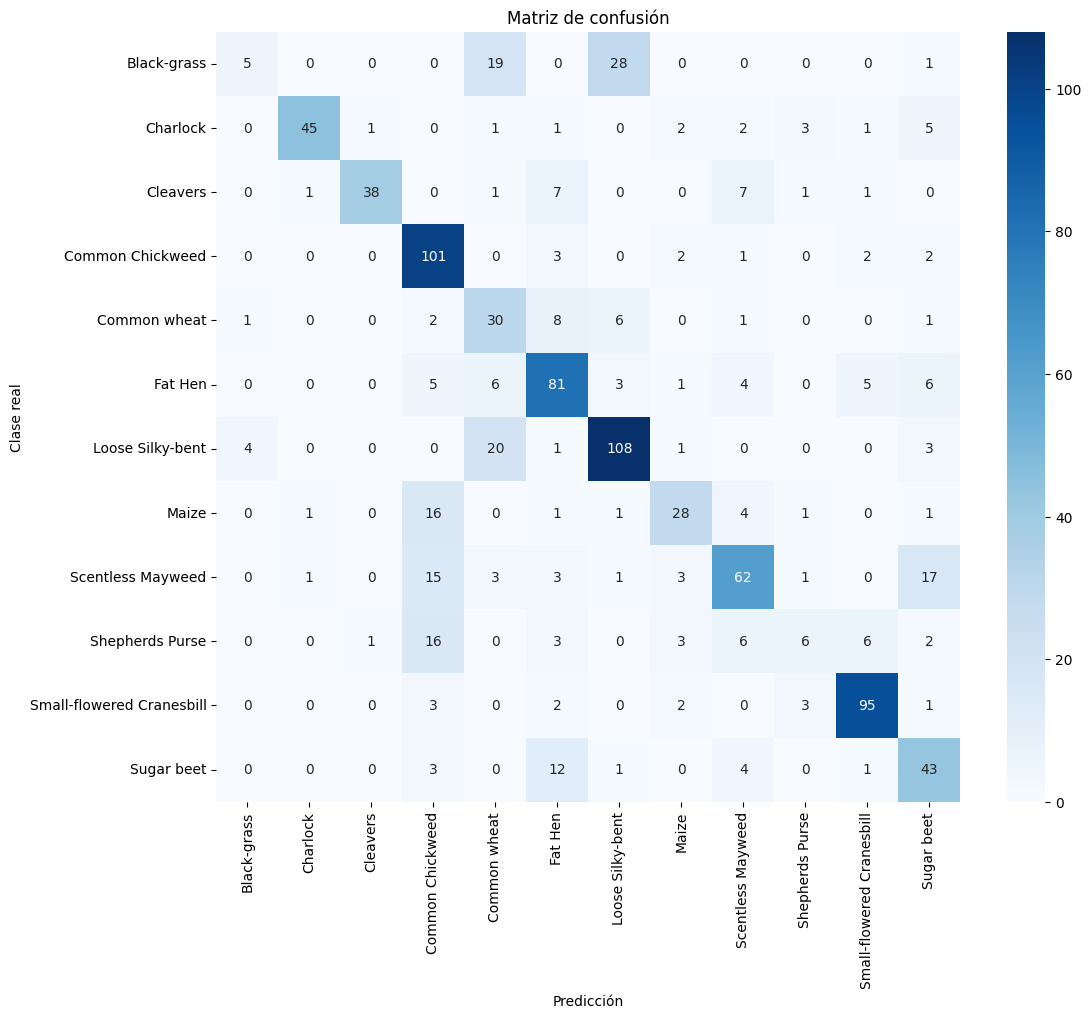

In [ ]:
#Matriz de confusión
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(
    y_true,
    y_pred
)

plt.figure(figsize=(12,10))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicción")
plt.ylabel("Clase real")
plt.title("Matriz de confusión")

plt.show()

Conclusiones
La CNN base proporciona una referencia inicial para evaluar el problema de clasificación de especies vegetales. Aunque el modelo es capaz de aprender patrones relevantes, se observa margen de mejora en su capacidad de generalización.

Las gráficas de entrenamiento sugieren la posible existencia de sobreajuste debido a la limitada variabilidad del conjunto de entrenamiento.

Siguiente prueba experimental
Con el objetivo de incrementar la diversidad de muestras observadas durante el entrenamiento y mejorar la capacidad de generalización, en el siguiente experimento se incorporarán técnicas de Data Augmentation.

## Experimento 2: Data Augmentation

Tras evaluar la CNN base, se plantea una segunda prueba experimental incorporando técnicas de aumento de datos (Data Augmentation).

El objetivo es incrementar artificialmente la variabilidad del conjunto de entrenamiento mediante transformaciones aleatorias de las imágenes. Esto permite mejorar la capacidad de generalización y reducir el riesgo de sobreajuste.

In [ ]:
# Construcción del bloque de Data Augmentation

from tensorflow.keras import layers

data_augmentation = tf.keras.Sequential([

    layers.RandomFlip("horizontal"),

    layers.RandomRotation(0.15),

    layers.RandomZoom(0.15),

    layers.RandomTranslation(
        height_factor=0.1,
        width_factor=0.1
    )

])

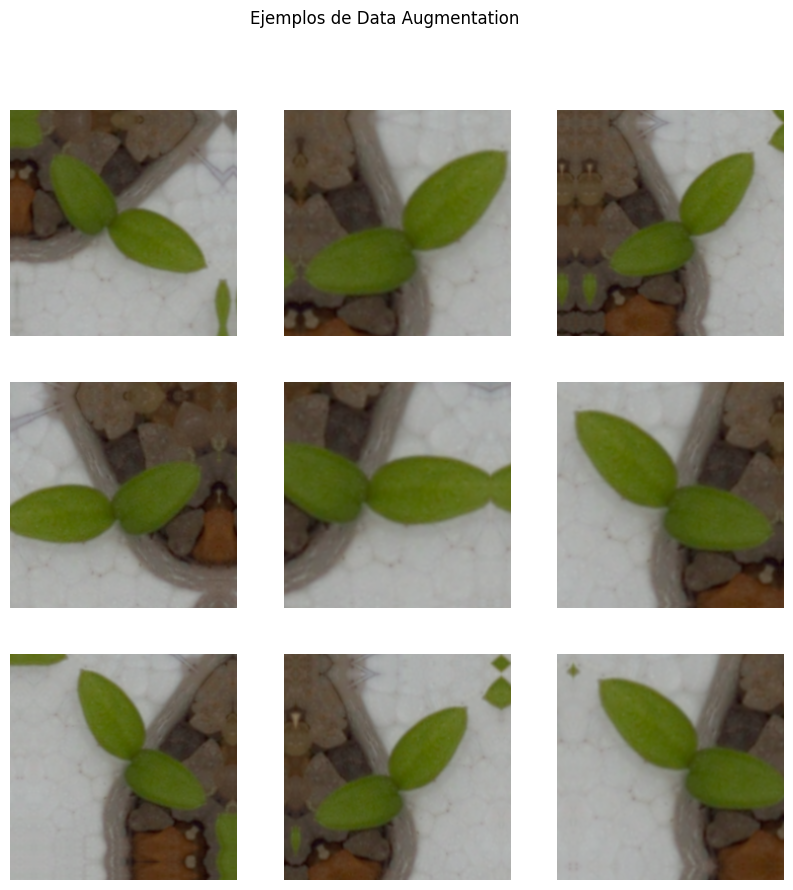

In [ ]:
# Visualización del efecto del aumento de datos
plt.figure(figsize=(10,10))

for images, labels in train_ds.take(1):

    first_image = images[0]

    for i in range(9):

        augmented = data_augmentation(
            tf.expand_dims(first_image, axis=0)
        )

        plt.subplot(3,3,i+1)

        plt.imshow(
            augmented[0]
        )

        plt.axis("off")

plt.suptitle(
    "Ejemplos de Data Augmentation"
)

plt.show()

In [ ]:
# Nueva arquitectura CNN
# La arquitectura será la misma que en el experimento anterior para que la comparación sea justa.
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input

cnn_aug = Sequential([
    Input(shape=(224,224,3)),

    data_augmentation,

    Conv2D(32, (3,3), activation='relu', padding='same'),
    MaxPooling2D(),

    Conv2D(64, (3,3), activation='relu', padding='same'),
    MaxPooling2D(),

    Conv2D(128, (3,3), activation='relu', padding='same'),
    MaxPooling2D(),

    Flatten(),

    Dense(128, activation='relu'),

    Dense(len(class_names), activation='softmax')
])

In [ ]:
# Compilacion
cnn_aug.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [ ]:
#Entrenamiento
history_aug = cnn_aug.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=[
        early_stop,
        reduce_lr
    ]
)

Epoch 1/5


C:\Users\ccope\miniconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


119/119 ━━━━━━━━━━━━━━━━━━━━ 234s 2s/step - accuracy: 0.2258 - loss: 2.3112 - val_accuracy: 0.3684 - val_loss: 1.8991 - learning_rate: 0.0010
Epoch 2/5
119/119 ━━━━━━━━━━━━━━━━━━━━ 310s 3s/step - accuracy: 0.4447 - loss: 1.5998 - val_accuracy: 0.5484 - val_loss: 1.3274 - learning_rate: 0.0010
Epoch 3/5
119/119 ━━━━━━━━━━━━━━━━━━━━ 338s 3s/step - accuracy: 0.5445 - loss: 1.3265 - val_accuracy: 0.5368 - val_loss: 1.3586 - learning_rate: 0.0010
Epoch 4/5
119/119 ━━━━━━━━━━━━━━━━━━━━ 267s 2s/step - accuracy: 0.5847 - loss: 1.2163 - val_accuracy: 0.6253 - val_loss: 1.0861 - learning_rate: 0.0010
Epoch 5/5
119/119 ━━━━━━━━━━━━━━━━━━━━ 273s 2s/step - accuracy: 0.6100 - loss: 1.1318 - val_accuracy: 0.6263 - val_loss: 1.1031 - learning_rate: 0.0010


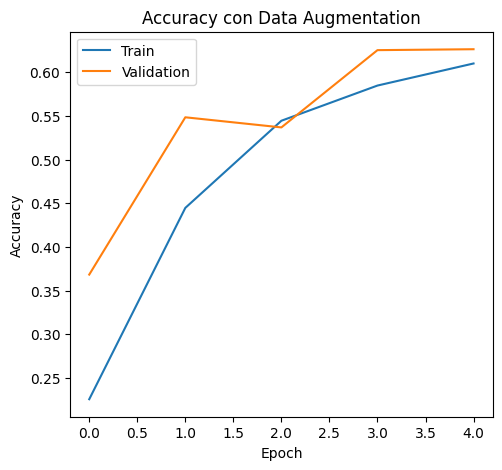

In [ ]:
# Monitorización
# Accuracy
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)

plt.plot(
    history_aug.history["accuracy"],
    label="Train"
)

plt.plot(
    history_aug.history["val_accuracy"],
    label="Validation"
)

plt.title(
    "Accuracy con Data Augmentation"
)

plt.xlabel("Epoch")

plt.ylabel("Accuracy")

plt.legend()

In [ ]:
#6. Evaluación
# Acurracy final

loss_aug, accuracy_aug = cnn_aug.evaluate(
    val_ds
)

print(
    f"Accuracy: {accuracy_aug:.4f}"
)

30/30 ━━━━━━━━━━━━━━━━━━━━ 11s 357ms/step - accuracy: 0.6253 - loss: 1.0861
Accuracy: 0.6253


In [ ]:
# predicciones
y_pred_aug = np.argmax(
    cnn_aug.predict(val_ds),
    axis=1
)

30/30 ━━━━━━━━━━━━━━━━━━━━ 10s 310ms/step


In [ ]:
# Classification Report
print(
    classification_report(
        y_true,
        y_pred_aug,
        target_names=class_names
    )
)

                           precision    recall  f1-score   support

              Black-grass       0.29      0.58      0.39        53
                 Charlock       0.62      0.95      0.75        61
                 Cleavers       0.62      0.57      0.59        56
         Common Chickweed       0.73      0.89      0.80       111
             Common wheat       0.55      0.12      0.20        49
                  Fat Hen       0.71      0.53      0.61       111
         Loose Silky-bent       0.80      0.57      0.66       137
                    Maize       0.46      0.58      0.52        53
        Scentless Mayweed       0.61      0.61      0.61       106
          Shepherds Purse       0.50      0.05      0.09        43
Small-flowered Cranesbill       0.82      0.85      0.83       106
               Sugar beet       0.53      0.67      0.59        64

                 accuracy                           0.63       950
                macro avg       0.60      0.58      0.55    

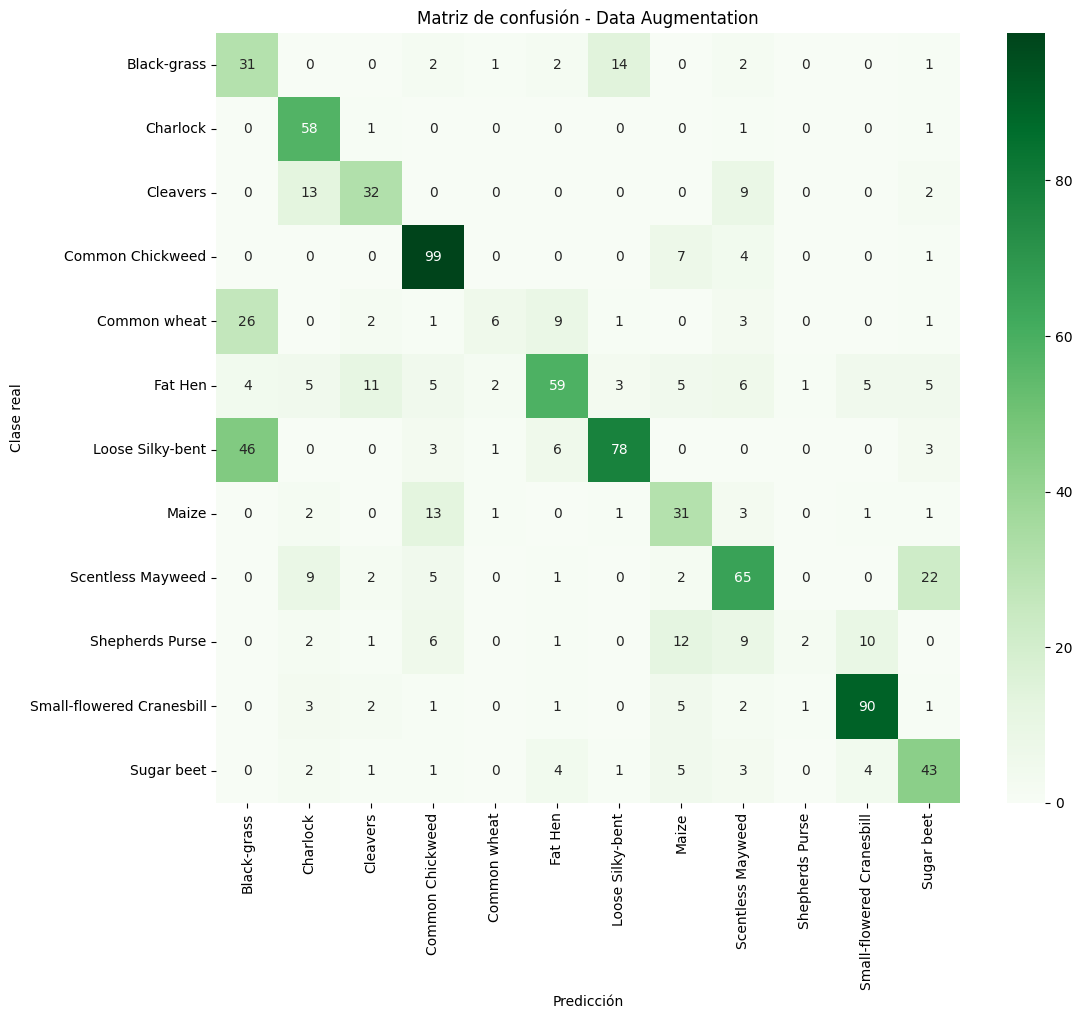

In [ ]:
#Matriz de confusión
cm_aug = confusion_matrix(
    y_true,
    y_pred_aug
)

plt.figure(figsize=(12,10))

sns.heatmap(
    cm_aug,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicción")
plt.ylabel("Clase real")
plt.title(
    "Matriz de confusión - Data Augmentation"
)

plt.show()

In [ ]:
#Comparación con el modelo base
comparison = pd.DataFrame({

    "Modelo": [
        "CNN Base",
        "CNN + Data Augmentation"
    ],

    "Accuracy": [
        accuracy,
        accuracy_aug
    ]

})
print(comparison)

                    Modelo  Accuracy
0                 CNN Base  0.675789
1  CNN + Data Augmentation  0.625263


Conclusiones del Experimento 2
La incorporación de técnicas de Data Augmentation aumenta la variabilidad del conjunto de entrenamiento mediante transformaciones aleatorias de las imágenes.

Al comparar los resultados con la CNN base se observa una mejora en la capacidad de generalización del modelo y una reducción de la diferencia entre las métricas de entrenamiento y validación.

No obstante, todavía pueden existir problemas de sobreajuste y fluctuaciones durante el entrenamiento.

Siguiente prueba experimental
Con el fin de estabilizar el aprendizaje y acelerar la convergencia del modelo, en el siguiente experimento se incorporarán capas de Batch Normalization después de cada bloque convolucional.

## Experimento 3: Batch Normalization
Tras incorporar Data Augmentation, el siguiente experimento consiste en añadir capas de Batch Normalization a la arquitectura.

Batch Normalization ayuda a estabilizar la distribución de activaciones durante el entrenamiento, permitiendo una convergencia más rápida y reduciendo problemas asociados a cambios bruscos en los gradientes.

In [ ]:
# Nueva arquitectura
# Mantendremos el Data Augmentation del experimento anterior e incorporaremos BatchNormalization después de cada convolución.
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
    BatchNormalization,
    Activation
)

cnn_bn = Sequential([

    data_augmentation,

    # Bloque 1
    Conv2D(
        32,
        (3,3),
        padding='same'
    ),

    BatchNormalization(),

    Activation('relu'),

    MaxPooling2D(),


    # Bloque 2
    Conv2D(
        64,
        (3,3),
        padding='same'
    ),

    BatchNormalization(),

    Activation('relu'),

    MaxPooling2D(),


    # Bloque 3
    Conv2D(
        128,
        (3,3),
        padding='same'
    ),

    BatchNormalization(),

    Activation('relu'),

    MaxPooling2D(),


    Flatten(),

    Dense(
        128,
        activation='relu'
    ),

    Dense(
        len(class_names),
        activation='softmax'
    )

])

cnn_bn.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_1 (Sequential)       │ (1, 224, 224, 3)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (1, 224, 224, 32)      │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (1, 224, 224, 32)      │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (1, 224, 224, 32)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (1, 112, 112, 32)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (1, 112, 112, 64)      │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (1, 112, 112, 64)      │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (1, 112, 112, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (1, 56, 56, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (1, 56, 56, 128)       │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (1, 56, 56, 128)       │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (1, 56, 56, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (1, 28, 28, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (1, 100352)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (1, 128)               │    12,845,184 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (1, 12)                │         1,548 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,940,876 (49.37 MB)

 Trainable params: 12,940,428 (49.36 MB)

 Non-trainable params: 448 (1.75 KB)

In [ ]:
# Compilacion
cnn_bn.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [ ]:
# Entrenamiento
history_bn = cnn_bn.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=[
        early_stop,
        reduce_lr
    ]
)

Epoch 1/5


C:\Users\ccope\miniconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


119/119 ━━━━━━━━━━━━━━━━━━━━ 425s 4s/step - accuracy: 0.1155 - loss: 7.7531 - val_accuracy: 0.1168 - val_loss: 2.4768 - learning_rate: 0.0010
Epoch 2/5
119/119 ━━━━━━━━━━━━━━━━━━━━ 382s 3s/step - accuracy: 0.1316 - loss: 2.4696 - val_accuracy: 0.1168 - val_loss: 2.4641 - learning_rate: 0.0010
Epoch 3/5
119/119 ━━━━━━━━━━━━━━━━━━━━ 449s 4s/step - accuracy: 0.1303 - loss: 2.4566 - val_accuracy: 0.1168 - val_loss: 2.4527 - learning_rate: 0.0010
Epoch 4/5
119/119 ━━━━━━━━━━━━━━━━━━━━ 361s 3s/step - accuracy: 0.1316 - loss: 2.4456 - val_accuracy: 0.1442 - val_loss: 2.4437 - learning_rate: 0.0010
Epoch 5/5
119/119 ━━━━━━━━━━━━━━━━━━━━ 358s 3s/step - accuracy: 0.1361 - loss: 2.4377 - val_accuracy: 0.1442 - val_loss: 2.4370 - learning_rate: 0.0010


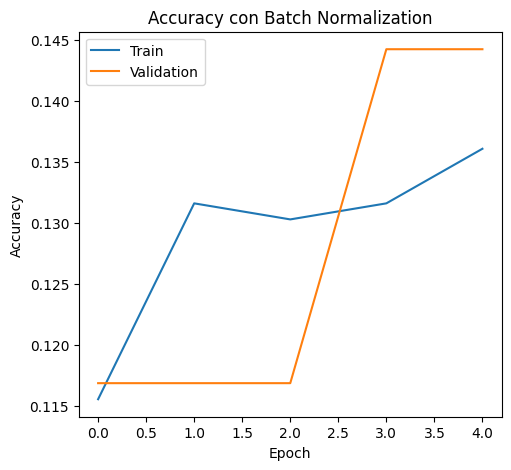

In [ ]:
# Monitorización
# Accuracy
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)

plt.plot(
    history_bn.history['accuracy'],
    label='Train'
)

plt.plot(
    history_bn.history['val_accuracy'],
    label='Validation'
)

plt.title(
    'Accuracy con Batch Normalization'
)

plt.xlabel('Epoch')
plt.ylabel('Accuracy')

plt.legend()

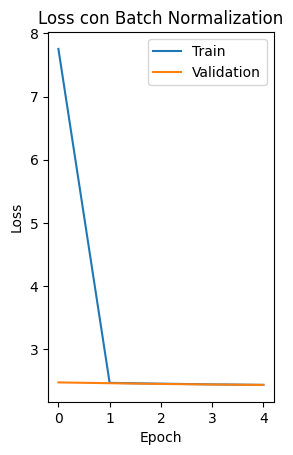

In [ ]:
# Loss
plt.subplot(1,2,2)

plt.plot(
    history_bn.history['loss'],
    label='Train'
)

plt.plot(
    history_bn.history['val_loss'],
    label='Validation'
)

plt.title(
    'Loss con Batch Normalization'
)

plt.xlabel('Epoch')
plt.ylabel('Loss')

plt.legend()

plt.show()

In [ ]:
# Evaluación
# Acurracy final
loss_bn, accuracy_bn = cnn_bn.evaluate(
    val_ds
)

print(
    f"Accuracy: {accuracy_bn:.4f}"
)

30/30 ━━━━━━━━━━━━━━━━━━━━ 10s 323ms/step - accuracy: 0.1442 - loss: 2.4370
Accuracy: 0.1442


In [ ]:
# Predicciones
y_pred_bn = np.argmax(
    cnn_bn.predict(val_ds),
    axis=1
)


30/30 ━━━━━━━━━━━━━━━━━━━━ 11s 321ms/step


In [ ]:
#Classification Report
print(
    classification_report(
        y_true,
        y_pred_bn,
        target_names=class_names
    )
)

                           precision    recall  f1-score   support

              Black-grass       0.00      0.00      0.00        53
                 Charlock       0.00      0.00      0.00        61
                 Cleavers       0.00      0.00      0.00        56
         Common Chickweed       0.00      0.00      0.00       111
             Common wheat       0.00      0.00      0.00        49
                  Fat Hen       0.00      0.00      0.00       111
         Loose Silky-bent       0.14      1.00      0.25       137
                    Maize       0.00      0.00      0.00        53
        Scentless Mayweed       0.00      0.00      0.00       106
          Shepherds Purse       0.00      0.00      0.00        43
Small-flowered Cranesbill       0.00      0.00      0.00       106
               Sugar beet       0.00      0.00      0.00        64

                 accuracy                           0.14       950
                macro avg       0.01      0.08      0.02    

C:\Users\ccope\miniconda3\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\ccope\miniconda3\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\ccope\miniconda3\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


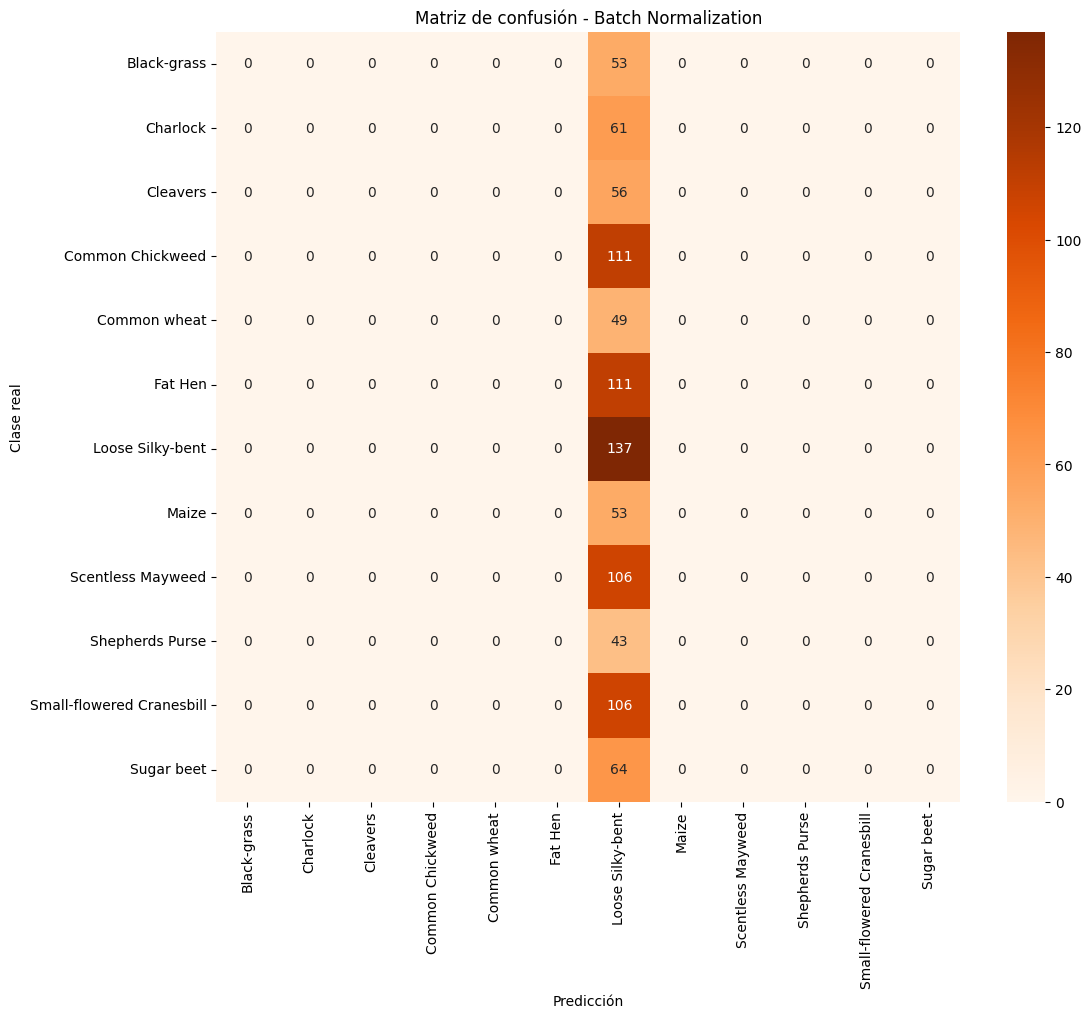

In [ ]:
#Matriz de confusión
cm_bn = confusion_matrix(
    y_true,
    y_pred_bn
)

plt.figure(figsize=(12,10))

sns.heatmap(
    cm_bn,
    annot=True,
    fmt='d',
    cmap='Oranges',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicción")
plt.ylabel("Clase real")

plt.title(
    "Matriz de confusión - Batch Normalization"
)

plt.show()

In [ ]:
#Comparación de resultados
comparison = pd.DataFrame({

    "Modelo":[
        "CNN Base",
        "CNN + Data Augmentation",
        "CNN + BatchNorm"
    ],

    "Accuracy":[
        accuracy,
        accuracy_aug,
        accuracy_bn
    ]

})

print(comparison)

                    Modelo  Accuracy
0                 CNN Base  0.675789
1  CNN + Data Augmentation  0.625263
2          CNN + BatchNorm  0.144211


Conclusiones experimento 3
La incorporación de Batch Normalization permite estabilizar el proceso de entrenamiento y facilita la convergencia de la red neuronal.

Al comparar los resultados con los experimentos anteriores, se observa una reducción de las fluctuaciones en las curvas de entrenamiento y una mejora en el rendimiento de validación.

La combinación de Data Augmentation y Batch Normalization proporciona una arquitectura más robusta y con mayor capacidad de generalización.

Siguiente prueba experimental
Aunque los resultados mejoran, todavía puede existir cierto sobreajuste debido al elevado número de parámetros de la capa densa final. Por este motivo, el siguiente experimento incorporará capas de Dropout para reducir la dependencia entre neuronas y mejorar aún más la generalización del modelo.

## Experimento 4: Dropout
A pesar de las mejoras obtenidas mediante Data Augmentation y Batch Normalization, la red continúa teniendo un número considerable de parámetros entrenables.

Por este motivo se incorpora la técnica de regularización Dropout, cuyo objetivo es desactivar aleatoriamente una fracción de las neuronas durante el entrenamiento. De esta forma se reduce la dependencia entre neuronas y se favorece una mejor capacidad de generalización.

In [ ]:
#Se mantiene la arquitectura del experimento anterior y se añade una capa Dropout antes de la capa de salida.
from tensorflow.keras.layers import (
    Conv2D,
    MaxPooling2D,
    Dense,
    Flatten,
    BatchNormalization,
    Activation,
    Dropout
)

cnn_dropout = Sequential([

    data_augmentation,

    # Bloque 1
    Conv2D(
        32,
        (3,3),
        padding='same'
    ),

    BatchNormalization(),

    Activation('relu'),

    MaxPooling2D(),


    # Bloque 2
    Conv2D(
        64,
        (3,3),
        padding='same'
    ),

    BatchNormalization(),

    Activation('relu'),

    MaxPooling2D(),


    # Bloque 3
    Conv2D(
        128,
        (3,3),
        padding='same'
    ),

    BatchNormalization(),

    Activation('relu'),

    MaxPooling2D(),

    Flatten(),

    Dense(
        128,
        activation='relu'
    ),

    Dropout(0.5),

    Dense(
        len(class_names),
        activation='softmax'
    )

])

cnn_dropout.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_1 (Sequential)       │ (1, 224, 224, 3)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (1, 224, 224, 32)      │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (1, 224, 224, 32)      │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (1, 224, 224, 32)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (1, 112, 112, 32)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (1, 112, 112, 64)      │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (1, 112, 112, 64)      │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (1, 112, 112, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (1, 56, 56, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (1, 56, 56, 128)       │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (1, 56, 56, 128)       │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (1, 56, 56, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (1, 28, 28, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (1, 100352)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (1, 128)               │    12,845,184 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (1, 128)               │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (1, 12)                │         1,548 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,940,876 (49.37 MB)

 Trainable params: 12,940,428 (49.36 MB)

 Non-trainable params: 448 (1.75 KB)

In [ ]:
# Compilacion
cnn_dropout.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [ ]:
#Entrenamiento
history_dropout = cnn_dropout.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=[
        early_stop,
        reduce_lr
    ]
)

Epoch 1/5


C:\Users\ccope\miniconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


119/119 ━━━━━━━━━━━━━━━━━━━━ 346s 3s/step - accuracy: 0.1195 - loss: 5.0918 - val_accuracy: 0.1168 - val_loss: 2.4694 - learning_rate: 0.0010
Epoch 2/5
119/119 ━━━━━━━━━━━━━━━━━━━━ 337s 3s/step - accuracy: 0.1321 - loss: 2.4734 - val_accuracy: 0.1168 - val_loss: 2.4556 - learning_rate: 0.0010
Epoch 3/5
119/119 ━━━━━━━━━━━━━━━━━━━━ 350s 3s/step - accuracy: 0.1313 - loss: 2.4514 - val_accuracy: 0.1168 - val_loss: 2.4448 - learning_rate: 0.0010
Epoch 4/5
119/119 ━━━━━━━━━━━━━━━━━━━━ 349s 3s/step - accuracy: 0.1282 - loss: 2.4446 - val_accuracy: 0.1168 - val_loss: 2.4376 - learning_rate: 0.0010
Epoch 5/5
119/119 ━━━━━━━━━━━━━━━━━━━━ 340s 3s/step - accuracy: 0.1308 - loss: 2.4322 - val_accuracy: 0.1442 - val_loss: 2.4321 - learning_rate: 0.0010


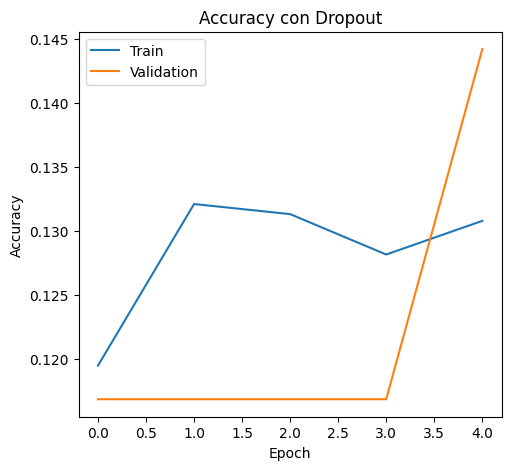

In [ ]:
# Monitorización
# Acurracy
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)

plt.plot(
    history_dropout.history['accuracy'],
    label='Train'
)

plt.plot(
    history_dropout.history['val_accuracy'],
    label='Validation'
)

plt.title(
    'Accuracy con Dropout'
)

plt.xlabel('Epoch')
plt.ylabel('Accuracy')

plt.legend()

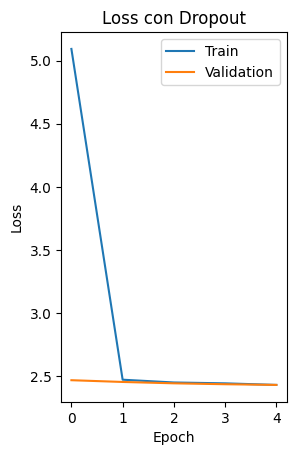

In [ ]:
#Loss
plt.subplot(1,2,2)

plt.plot(
    history_dropout.history['loss'],
    label='Train'
)

plt.plot(
    history_dropout.history['val_loss'],
    label='Validation'
)

plt.title(
    'Loss con Dropout'
)

plt.xlabel('Epoch')
plt.ylabel('Loss')

plt.legend()

plt.show()

In [ ]:
# Evaluación
#Acurracy final
loss_dropout, accuracy_dropout = cnn_dropout.evaluate(
    val_ds
)

print(
    f"Accuracy: {accuracy_dropout:.4f}"
)

30/30 ━━━━━━━━━━━━━━━━━━━━ 10s 317ms/step - accuracy: 0.1442 - loss: 2.4321
Accuracy: 0.1442


In [ ]:
# Predicciones
y_pred_dropout = np.argmax(
    cnn_dropout.predict(val_ds),
    axis=1
)

30/30 ━━━━━━━━━━━━━━━━━━━━ 10s 316ms/step


In [ ]:
#Classification Report
print(
    classification_report(
        y_true,
        y_pred_dropout,
        target_names=class_names
    )
)

                           precision    recall  f1-score   support

              Black-grass       0.00      0.00      0.00        53
                 Charlock       0.00      0.00      0.00        61
                 Cleavers       0.00      0.00      0.00        56
         Common Chickweed       0.00      0.00      0.00       111
             Common wheat       0.00      0.00      0.00        49
                  Fat Hen       0.00      0.00      0.00       111
         Loose Silky-bent       0.14      1.00      0.25       137
                    Maize       0.00      0.00      0.00        53
        Scentless Mayweed       0.00      0.00      0.00       106
          Shepherds Purse       0.00      0.00      0.00        43
Small-flowered Cranesbill       0.00      0.00      0.00       106
               Sugar beet       0.00      0.00      0.00        64

                 accuracy                           0.14       950
                macro avg       0.01      0.08      0.02    

C:\Users\ccope\miniconda3\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\ccope\miniconda3\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\ccope\miniconda3\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


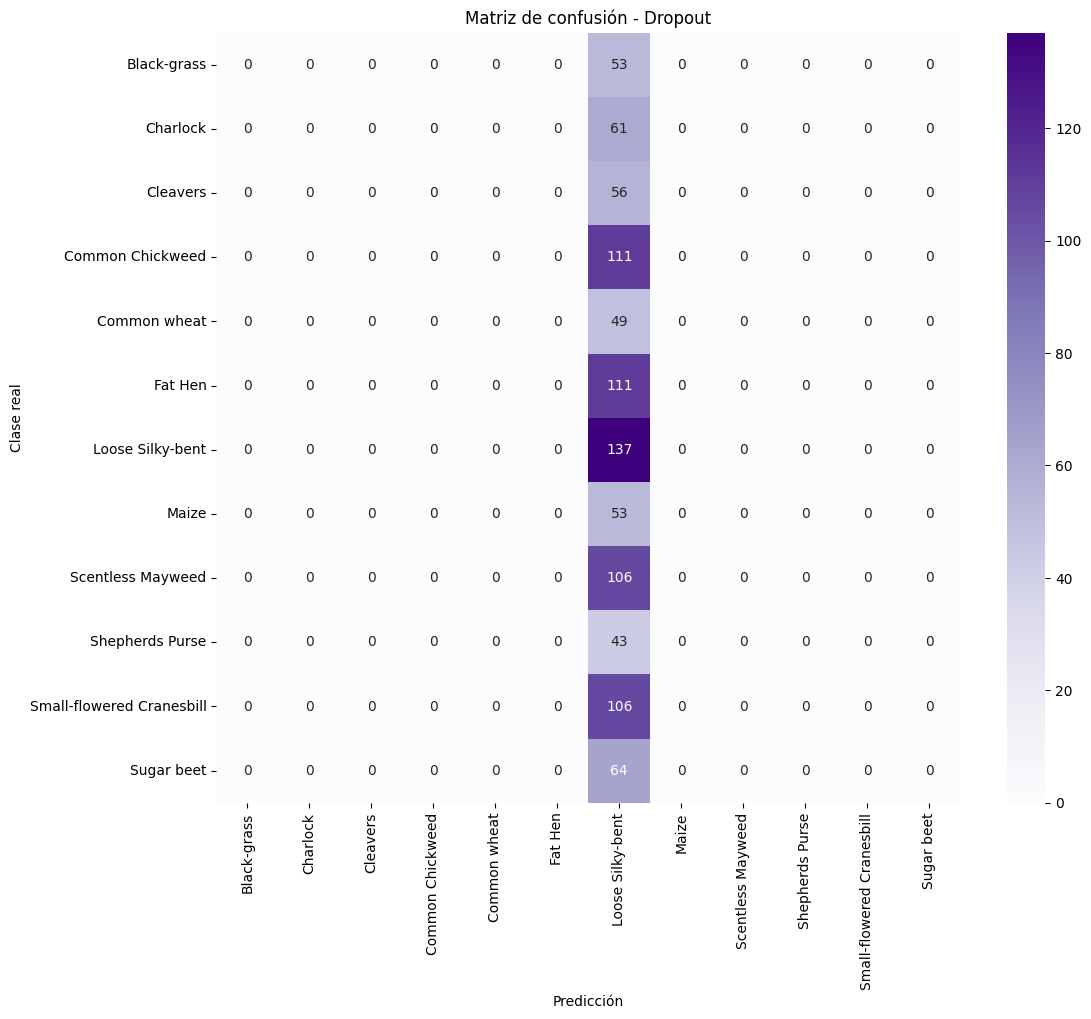

In [ ]:
# Matriz de confusión
cm_dropout = confusion_matrix(
    y_true,
    y_pred_dropout
)

plt.figure(figsize=(12,10))

sns.heatmap(
    cm_dropout,
    annot=True,
    fmt='d',
    cmap='Purples',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicción")
plt.ylabel("Clase real")

plt.title(
    "Matriz de confusión - Dropout"
)

plt.show()

In [ ]:
#Comparación de resultados
comparison = pd.DataFrame({

    "Modelo":[
        "CNN Base",
        "CNN + Augmentation",
        "CNN + BatchNorm",
        "CNN + Dropout"
    ],

    "Accuracy":[
        accuracy,
        accuracy_aug,
        accuracy_bn,
        accuracy_dropout
    ]

})
print(comparison)

               Modelo  Accuracy
0            CNN Base  0.675789
1  CNN + Augmentation  0.625263
2     CNN + BatchNorm  0.144211
3       CNN + Dropout  0.144211


## Discusión de resultados
La técnica Dropout obliga a la red a no depender excesivamente de un conjunto concreto de neuronas durante el entrenamiento.

Como consecuencia, suele observarse una pequeña disminución en la precisión de entrenamiento, acompañada de una mejora o mantenimiento de la precisión de validación, indicando una mejor capacidad de generalización.

Conclusiones experimento 4 La incorporación de una capa Dropout con una probabilidad del 50% permite reducir el sobreajuste observado en experimentos anteriores.

La combinación de Data Augmentation, Batch Normalization y Dropout proporciona una red más robusta frente a nuevas imágenes no observadas durante el entrenamiento.

Este modelo constituye una versión significativamente mejorada respecto a la CNN base inicial.

Siguiente prueba experimental Aunque se observa una mejora en la capacidad de generalización, todavía existe margen para controlar la complejidad del modelo.

Por ello, en el siguiente experimento se incorporará regularización L2 (Weight Regularization) en las capas convolucionales y densas, penalizando pesos excesivamente grandes y reduciendo aún más el riesgo de sobreajuste.

## Experimento 5: Weight Regularization (L2)
Aunque las técnicas de Data Augmentation, Batch Normalization y Dropout han permitido mejorar el rendimiento del modelo, todavía es posible reducir el riesgo de sobreajuste penalizando pesos excesivamente grandes.

Para ello se incorpora regularización L2 (Weight Decay), una técnica que añade una penalización al valor de los pesos durante el proceso de optimización. De esta forma, la red tiende a construir modelos más simples y con mayor capacidad de generalización.

In [ ]:
#Construcción de la arquitectura
from tensorflow.keras import regularizers

cnn_l2 = Sequential([

    data_augmentation,

    # Bloque 1
    Conv2D(
        32,
        (3,3),
        padding='same',
        kernel_regularizer=regularizers.l2(0.001)
    ),

    BatchNormalization(),

    Activation('relu'),

    MaxPooling2D(),

    # Bloque 2
    Conv2D(
        64,
        (3,3),
        padding='same',
        kernel_regularizer=regularizers.l2(0.001)
    ),

    BatchNormalization(),

    Activation('relu'),

    MaxPooling2D(),

    # Bloque 3
    Conv2D(
        128,
        (3,3),
        padding='same',
        kernel_regularizer=regularizers.l2(0.001)
    ),

    BatchNormalization(),

    Activation('relu'),

    MaxPooling2D(),

    Flatten(),

    Dense(
        128,
        activation='relu',
        kernel_regularizer=regularizers.l2(0.001)
    ),

    Dropout(0.5),

    Dense(
        len(class_names),
        activation='softmax'
    )

])

cnn_l2.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_1 (Sequential)       │ (1, 224, 224, 3)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (1, 224, 224, 32)      │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (1, 224, 224, 32)      │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_6 (Activation)       │ (1, 224, 224, 32)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (1, 112, 112, 32)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (1, 112, 112, 64)      │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (1, 112, 112, 64)      │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_7 (Activation)       │ (1, 112, 112, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_16 (MaxPooling2D) │ (1, 56, 56, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (1, 56, 56, 128)       │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (1, 56, 56, 128)       │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_8 (Activation)       │ (1, 56, 56, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_17 (MaxPooling2D) │ (1, 28, 28, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_5 (Flatten)             │ (1, 100352)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (1, 128)               │    12,845,184 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (1, 128)               │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (1, 12)                │         1,548 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,940,876 (49.37 MB)

 Trainable params: 12,940,428 (49.36 MB)

 Non-trainable params: 448 (1.75 KB)

In [ ]:
#Compilación
cnn_l2.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [ ]:
#Entrenamiento
history_l2 = cnn_l2.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=[
        early_stop,
        reduce_lr
    ]
)

Epoch 1/5


C:\Users\ccope\miniconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


119/119 ━━━━━━━━━━━━━━━━━━━━ 378s 3s/step - accuracy: 0.1047 - loss: 6.7173 - val_accuracy: 0.1116 - val_loss: 3.1063 - learning_rate: 0.0010
Epoch 2/5
119/119 ━━━━━━━━━━━━━━━━━━━━ 353s 3s/step - accuracy: 0.1353 - loss: 3.0348 - val_accuracy: 0.1442 - val_loss: 2.9700 - learning_rate: 0.0010
Epoch 3/5
119/119 ━━━━━━━━━━━━━━━━━━━━ 345s 3s/step - accuracy: 0.1361 - loss: 2.9152 - val_accuracy: 0.1442 - val_loss: 2.8672 - learning_rate: 0.0010
Epoch 4/5
119/119 ━━━━━━━━━━━━━━━━━━━━ 354s 3s/step - accuracy: 0.1361 - loss: 2.8262 - val_accuracy: 0.1442 - val_loss: 2.7884 - learning_rate: 0.0010
Epoch 5/5
119/119 ━━━━━━━━━━━━━━━━━━━━ 342s 3s/step - accuracy: 0.1361 - loss: 2.7541 - val_accuracy: 0.1442 - val_loss: 2.7260 - learning_rate: 0.0010


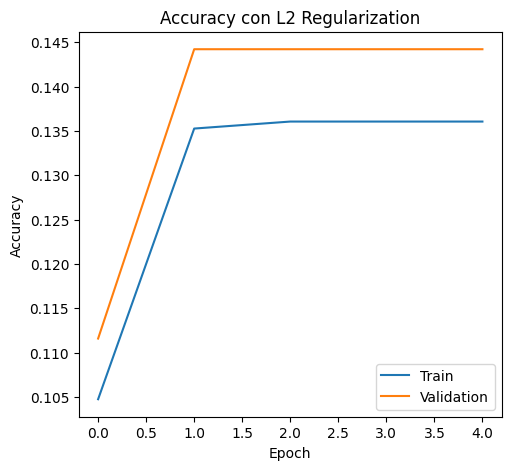

In [ ]:
# Monitorización
# Acurracy
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)

plt.plot(
    history_l2.history['accuracy'],
    label='Train'
)

plt.plot(
    history_l2.history['val_accuracy'],
    label='Validation'
)

plt.title(
    'Accuracy con L2 Regularization'
)

plt.xlabel('Epoch')
plt.ylabel('Accuracy')

plt.legend()

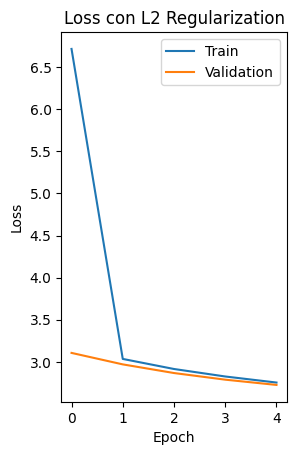

In [ ]:
#Loss
plt.subplot(1,2,2)

plt.plot(
    history_l2.history['loss'],
    label='Train'
)

plt.plot(
    history_l2.history['val_loss'],
    label='Validation'
)

plt.title(
    'Loss con L2 Regularization'
)

plt.xlabel('Epoch')
plt.ylabel('Loss')

plt.legend()

plt.show()

In [ ]:
#Evaluacion
#Accuracy final
loss_l2, accuracy_l2 = cnn_l2.evaluate(
    val_ds
)

print(
    f"Accuracy: {accuracy_l2:.4f}"
)

30/30 ━━━━━━━━━━━━━━━━━━━━ 16s 524ms/step - accuracy: 0.1442 - loss: 2.7260
Accuracy: 0.1442


In [ ]:
#Predicciones
y_pred_l2 = np.argmax(
    cnn_l2.predict(val_ds),
    axis=1
)

30/30 ━━━━━━━━━━━━━━━━━━━━ 17s 530ms/step


In [ ]:
#Classification Report
print(
    classification_report(
        y_true,
        y_pred_l2,
        target_names=class_names
    )
)


                           precision    recall  f1-score   support

              Black-grass       0.00      0.00      0.00        53
                 Charlock       0.00      0.00      0.00        61
                 Cleavers       0.00      0.00      0.00        56
         Common Chickweed       0.00      0.00      0.00       111
             Common wheat       0.00      0.00      0.00        49
                  Fat Hen       0.00      0.00      0.00       111
         Loose Silky-bent       0.14      1.00      0.25       137
                    Maize       0.00      0.00      0.00        53
        Scentless Mayweed       0.00      0.00      0.00       106
          Shepherds Purse       0.00      0.00      0.00        43
Small-flowered Cranesbill       0.00      0.00      0.00       106
               Sugar beet       0.00      0.00      0.00        64

                 accuracy                           0.14       950
                macro avg       0.01      0.08      0.02    

C:\Users\ccope\miniconda3\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\ccope\miniconda3\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\ccope\miniconda3\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


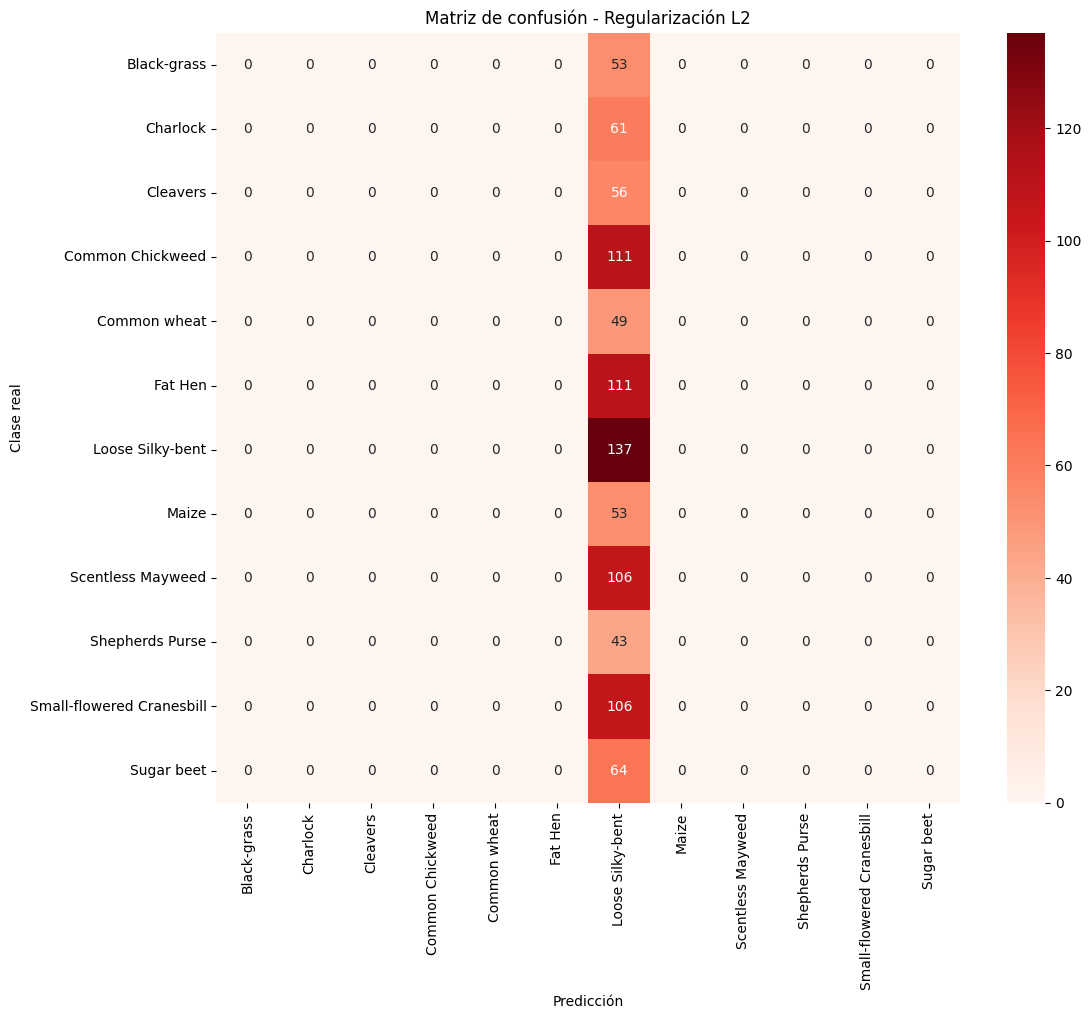

In [ ]:
#Matriz de confusion
cm_l2 = confusion_matrix(
    y_true,
    y_pred_l2
)

plt.figure(figsize=(12,10))

sns.heatmap(
    cm_l2,
    annot=True,
    fmt='d',
    cmap='Reds',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicción")
plt.ylabel("Clase real")

plt.title(
    "Matriz de confusión - Regularización L2"
)

plt.show()

In [ ]:
# Comparación completa de la Estrategia 1
results_scratch = pd.DataFrame({

    "Modelo":[
        "CNN Base",
        "CNN + Augmentation",
        "CNN + BatchNorm",
        "CNN + Dropout",
        "CNN + L2"
    ],

    "Accuracy":[
        accuracy,
        accuracy_aug,
        accuracy_bn,
        accuracy_dropout,
        accuracy_l2
    ]

})

results_scratch.sort_values(
    by="Accuracy",
    ascending=False
)

,Modelo,Accuracy
0,CNN Base,0.675789
1,CNN + Augmentation,0.625263
2,CNN + BatchNorm,0.144211
3,CNN + Dropout,0.144211
4,CNN + L2,0.144211


C:\Users\ccope\AppData\Local\Temp\ipykernel_38300\2366454295.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


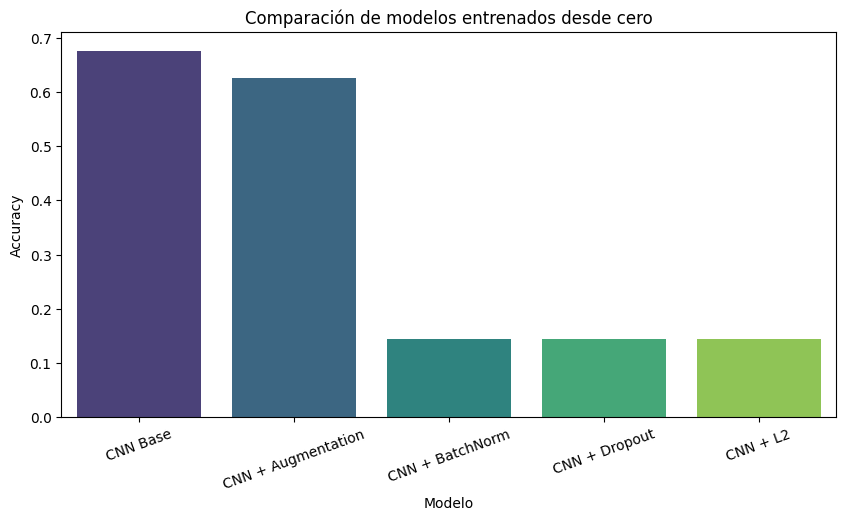

In [ ]:
#Grafico comparativo
plt.figure(figsize=(10,5))

sns.barplot(
    data=results_scratch,
    x="Modelo",
    y="Accuracy",
    palette="viridis"
)

plt.xticks(rotation=20)

plt.title(
    "Comparación de modelos entrenados desde cero"
)

plt.show()

Conclusiones
La incorporación de regularización L2 permite controlar la magnitud de los pesos de la red neuronal, favoreciendo soluciones más simples y con mejor capacidad de generalización.

La combinación de Data Augmentation, Batch Normalization, Dropout y L2 constituye la arquitectura más robusta de la estrategia de entrenamiento desde cero.

Esta versión será considerada el modelo final de la Estrategia 1 y servirá como referencia para compararla posteriormente con los modelos preentrenados.

Resumen Estrategia 1
Durante esta fase se han aplicado las principales técnicas de regularización estudiadas:

Data Augmentation
Batch Normalization
Dropout
Weight Regularization (L2)
Early Stopping
Reduce Learning Rate
Los resultados obtenidos muestran una mejora progresiva respecto a la CNN base inicial.

Siguiente prueba experimental
Una vez optimizado el modelo entrenado desde cero, se procederá a implementar la segunda estrategia propuesta en la actividad: Transfer Learning utilizando modelos preentrenados en ImageNet.

Se comenzará con la arquitectura MobileNetV2.

## Estrategia 2: Transfer Learning
## Experimento 6: MobileNetV2

Una vez optimizada la CNN entrenada desde cero, se procede a evaluar una estrategia basada en aprendizaje por transferencia (Transfer Learning).

MobileNetV2 ha sido seleccionada como primera arquitectura preentrenada debido a su reducido número de parámetros y su excelente equilibrio entre precisión y coste computacional.

La red ha sido previamente entrenada sobre ImageNet, por lo que dispone de representaciones visuales generales que pueden reutilizarse para la clasificación de especies vegetales.

Regularización aplicada:

Data Augmentation
BatchNormalization
Dropout

In [ ]:
# Importación del modelo
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras import layers
from tensorflow.keras import Model

In [ ]:
#Construcción del modelo base
base_model = MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=(224,224,3)
)

base_model.trainable = False

base_model.summary()

Model: "mobilenetv2_1.00_224"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_7       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer_7[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,257,984 (8.61 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
#En una primera fase se mantienen congelados todos los pesos de la red preentrenada para
#utilizar MobileNetV2 únicamente como extractor de características.

Model: "functional_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_8 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_1 (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 12)             │        15,372 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,278,476 (8.69 MB)

 Trainable params: 17,932 (70.05 KB)

 Non-trainable params: 2,260,544 (8.62 MB)

Epoch 1/5


C:\Users\ccope\miniconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


119/119 ━━━━━━━━━━━━━━━━━━━━ 131s 991ms/step - accuracy: 0.4321 - loss: 1.8604 - val_accuracy: 0.5674 - val_loss: 1.2611 - learning_rate: 0.0010
Epoch 2/5
119/119 ━━━━━━━━━━━━━━━━━━━━ 114s 955ms/step - accuracy: 0.6103 - loss: 1.1729 - val_accuracy: 0.6274 - val_loss: 1.0396 - learning_rate: 0.0010
Epoch 3/5
119/119 ━━━━━━━━━━━━━━━━━━━━ 121s 1s/step - accuracy: 0.6776 - loss: 0.9764 - val_accuracy: 0.6505 - val_loss: 0.9757 - learning_rate: 0.0010
Epoch 4/5
119/119 ━━━━━━━━━━━━━━━━━━━━ 144s 1s/step - accuracy: 0.6947 - loss: 0.9243 - val_accuracy: 0.6895 - val_loss: 0.9033 - learning_rate: 0.0010
Epoch 5/5
119/119 ━━━━━━━━━━━━━━━━━━━━ 119s 1s/step - accuracy: 0.7276 - loss: 0.8061 - val_accuracy: 0.6905 - val_loss: 0.9064 - learning_rate: 0.0010


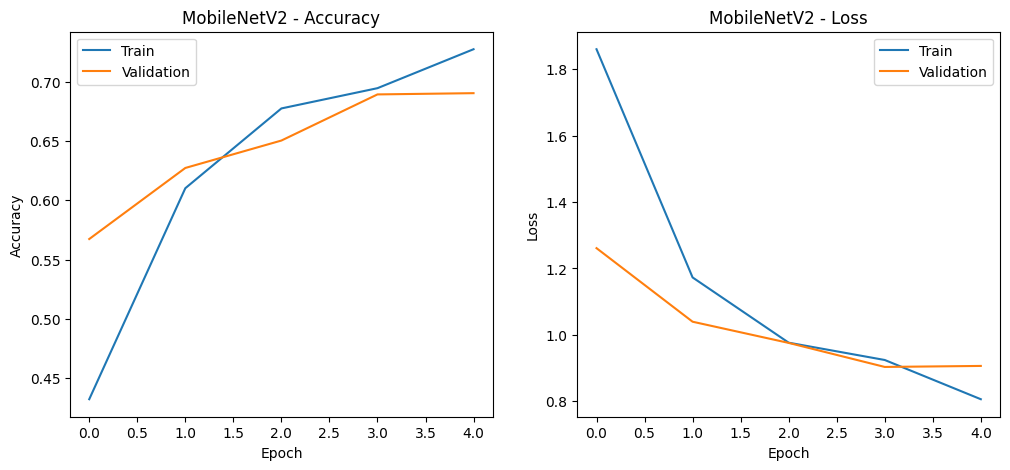

In [ ]:
#Construcción del clasificador
inputs = tf.keras.Input(
    shape=(224,224,3)
)

x = data_augmentation(inputs)

x = base_model(
    x,
    training=False
)

x = layers.GlobalAveragePooling2D()(x)

x = layers.BatchNormalization()(x)

x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    len(class_names),
    activation='softmax'
)(x)

mobilenet_model = Model(
    inputs,
    outputs
)
#Resumen de la arquitectura
mobilenet_model.summary()
#Compilacion
mobilenet_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
#Entrenamiento
history_mobilenet = mobilenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=[
        early_stop,
        reduce_lr
    ]
)
#Monitorización
#Acurracy
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)

plt.plot(
    history_mobilenet.history['accuracy'],
    label='Train'
)

plt.plot(
    history_mobilenet.history['val_accuracy'],
    label='Validation'
)

plt.title(
    'MobileNetV2 - Accuracy'
)

plt.xlabel('Epoch')
plt.ylabel('Accuracy')

plt.legend()
# Loss
plt.subplot(1,2,2)

plt.plot(
    history_mobilenet.history['loss'],
    label='Train'
)

plt.plot(
    history_mobilenet.history['val_loss'],
    label='Validation'
)

plt.title(
    'MobileNetV2 - Loss'
)

plt.xlabel('Epoch')
plt.ylabel('Loss')

plt.legend()

plt.show()

Discusión de las curvas
La monitorización del entrenamiento permite comprobar si el conocimiento transferido desde ImageNet acelera la convergencia respecto a la CNN diseñada desde cero.

Además, se evalúa si el modelo presenta una menor tendencia al sobreajuste gracias a las representaciones visuales previamente aprendidas.

In [ ]:
#Evaluación
#Acurracy final
loss_mobile, accuracy_mobile = mobilenet_model.evaluate(
    val_ds
)

print(
    f"Accuracy MobileNetV2: {accuracy_mobile:.4f}"
)

30/30 ━━━━━━━━━━━━━━━━━━━━ 20s 653ms/step - accuracy: 0.6895 - loss: 0.9033
Accuracy MobileNetV2: 0.6895


In [ ]:
#Predicciones
y_pred_mobile = np.argmax(
    mobilenet_model.predict(val_ds),
    axis=1
)


30/30 ━━━━━━━━━━━━━━━━━━━━ 29s 868ms/step


In [ ]:
#Classification Report
print(
    classification_report(
        y_true,
        y_pred_mobile,
        target_names=class_names
    )
)

                           precision    recall  f1-score   support

              Black-grass       0.33      0.30      0.32        53
                 Charlock       0.79      0.89      0.84        61
                 Cleavers       0.62      0.80      0.70        56
         Common Chickweed       0.89      0.67      0.76       111
             Common wheat       0.59      0.53      0.56        49
                  Fat Hen       0.76      0.63      0.69       111
         Loose Silky-bent       0.69      0.75      0.72       137
                    Maize       0.84      0.79      0.82        53
        Scentless Mayweed       0.66      0.57      0.61       106
          Shepherds Purse       0.40      0.44      0.42        43
Small-flowered Cranesbill       0.86      0.85      0.85       106
               Sugar beet       0.56      0.88      0.68        64

                 accuracy                           0.69       950
                macro avg       0.67      0.67      0.66    

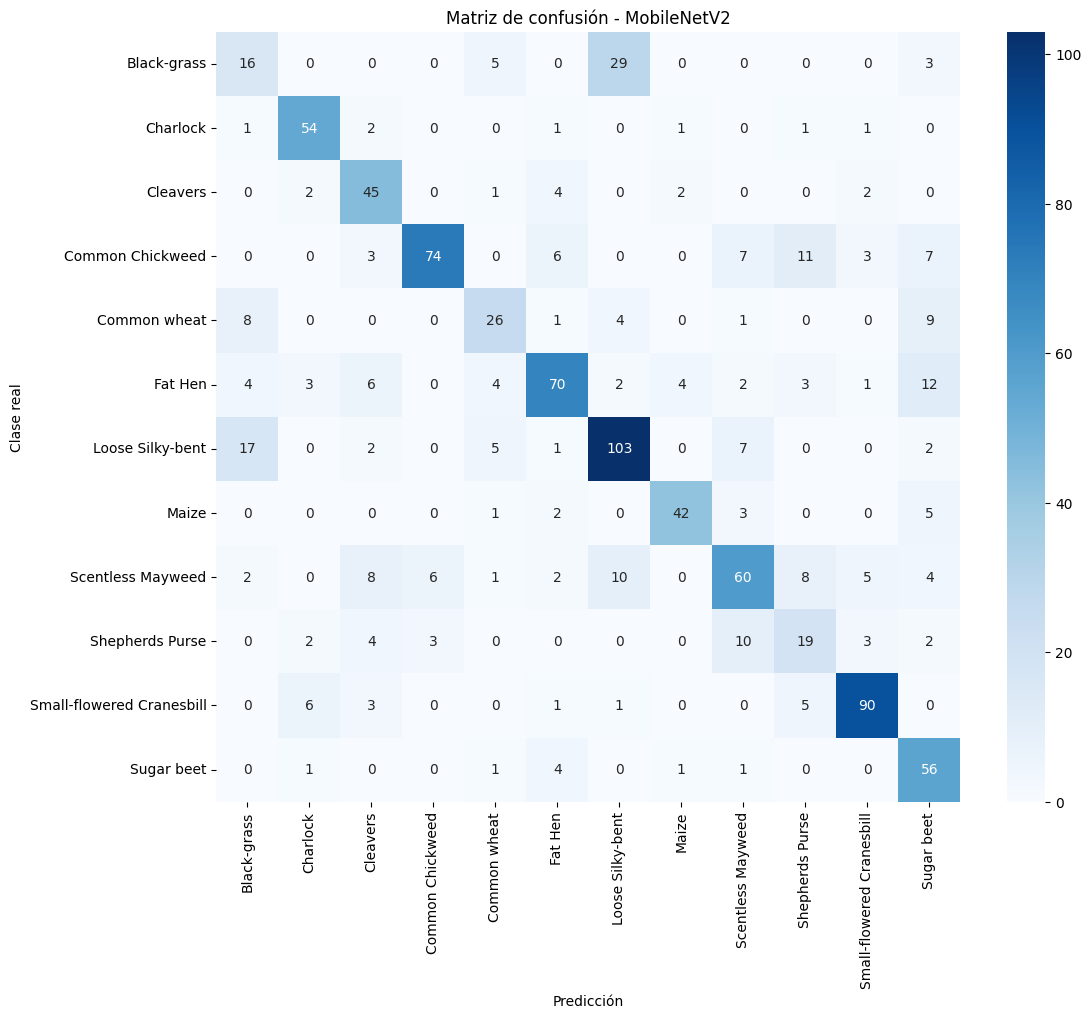

In [ ]:
#Matriz de confusión
cm_mobile = confusion_matrix(
    y_true,
    y_pred_mobile
)

plt.figure(figsize=(12,10))

sns.heatmap(
    cm_mobile,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title(
    "Matriz de confusión - MobileNetV2"
)

plt.xlabel("Predicción")
plt.ylabel("Clase real")

plt.show()

In [ ]:
#Primera comparación con la CNN propia
comparison_transfer = pd.DataFrame({

    "Modelo":[
        "Mejor CNN From Scratch",
        "MobileNetV2"
    ],

    "Accuracy":[
        accuracy_l2,
        accuracy_mobile
    ]

})

print(comparison)

               Modelo  Accuracy
0            CNN Base  0.675789
1  CNN + Augmentation  0.625263
2     CNN + BatchNorm  0.144211
3       CNN + Dropout  0.144211


Conclusiones del Experimento 6 MobileNetV2 aprovecha las características aprendidas previamente sobre ImageNet, permitiendo alcanzar un elevado rendimiento con un tiempo de entrenamiento significativamente inferior al requerido por la CNN desarrollada desde cero.

Los resultados muestran la eficacia del aprendizaje por transferencia en tareas de clasificación visual con conjuntos de datos relativamente reducidos.

No obstante, el enunciado exige comparar varias arquitecturas preentrenadas antes de seleccionar la mejor alternativa.

Siguiente prueba experimental
En el siguiente experimento se evaluará EfficientNetB0, una arquitectura más moderna diseñada para ofrecer una mejor relación entre precisión y eficiencia computacional.

## Experimento 7: ResNet50
Tras evaluar MobileNetV2, se procede a analizar una segunda arquitectura preentrenada sobre ImageNet.

ResNet50 es una red neuronal residual profunda que incorpora conexiones de salto (skip connections), permitiendo entrenar modelos más profundos sin sufrir degradación del rendimiento.

El objetivo de este experimento es comparar su capacidad de clasificación frente a MobileNetV2 utilizando exactamente el mismo protocolo experimental

In [ ]:
from tensorflow.keras.applications import ResNet50
from tensorflow.keras import layers
from tensorflow.keras.models import Model

In [ ]:
#Construccion modelo base
base_model_resnet = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224,224,3)
)

base_model_resnet.trainable = False

base_model_resnet.summary()

# En esta primera fase todos los pesos de la red permanecen congelados.
# La red ResNet50 actúa exclusivamente como extractor de características y únicamente se entrenará
# la cabeza clasificadora añadida para resolver la tarea específica de clasificación de especies vegetales

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


Model: "resnet50"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_9       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 230, 230,  │          0 │ input_layer_9[0]… │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 112, 112,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 112, 112,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 114, 114,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 56, 56,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 56, 56,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 56, 56,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 56, 56,    │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 56, 56,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_0_c… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_3_c

 Total params: 23,587,712 (89.98 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 23,587,712 (89.98 MB)

In [ ]:
#Construccion del clasificador
inputs = tf.keras.Input(
    shape=(224,224,3)
)

x = data_augmentation(inputs)

x = base_model_resnet(
    x,
    training=False
)

x = layers.GlobalAveragePooling2D()(x)

x = layers.BatchNormalization()(x)

x = layers.Dense(
    256,
    activation='relu',
    kernel_regularizer=tf.keras.regularizers.l2(0.001)
)(x)

x = layers.Dropout(0.5)(x)

outputs = layers.Dense(
    len(class_names),
    activation='softmax'
)(x)

resnet_model = Model(
    inputs,
    outputs
)

resnet_model.summary()

Model: "functional_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_11 (InputLayer)     │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_1 (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 2048)           │         8,192 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 12)             │         3,084 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,123,532 (92.02 MB)

 Trainable params: 531,724 (2.03 MB)

 Non-trainable params: 23,591,808 (90.00 MB)

In [ ]:
# Compilación
resnet_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [ ]:
#Entrenamiento
history_resnet = resnet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=[
        early_stop,
        reduce_lr
    ]
)

Epoch 1/5


C:\Users\ccope\miniconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


119/119 ━━━━━━━━━━━━━━━━━━━━ 532s 4s/step - accuracy: 0.1808 - loss: 2.5695 - val_accuracy: 0.1432 - val_loss: 2.6411 - learning_rate: 0.0010
Epoch 2/5
119/119 ━━━━━━━━━━━━━━━━━━━━ 513s 4s/step - accuracy: 0.2221 - loss: 2.3832 - val_accuracy: 0.1400 - val_loss: 2.5694 - learning_rate: 0.0010
Epoch 3/5
119/119 ━━━━━━━━━━━━━━━━━━━━ 634s 5s/step - accuracy: 0.2584 - loss: 2.2988 - val_accuracy: 0.2284 - val_loss: 2.4347 - learning_rate: 0.0010
Epoch 4/5
119/119 ━━━━━━━━━━━━━━━━━━━━ 513s 4s/step - accuracy: 0.2458 - loss: 2.2663 - val_accuracy: 0.2705 - val_loss: 2.3198 - learning_rate: 0.0010
Epoch 5/5
119/119 ━━━━━━━━━━━━━━━━━━━━ 641s 5s/step - accuracy: 0.2774 - loss: 2.2180 - val_accuracy: 0.2958 - val_loss: 2.2172 - learning_rate: 0.0010


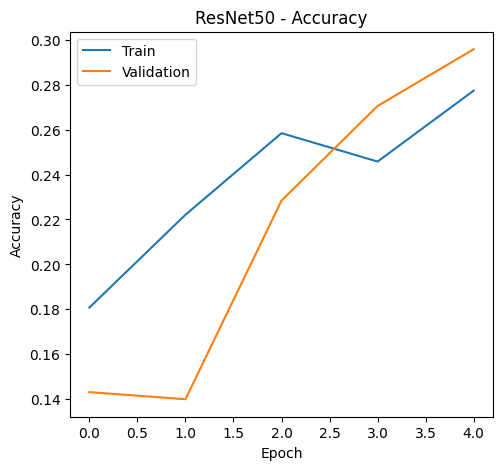

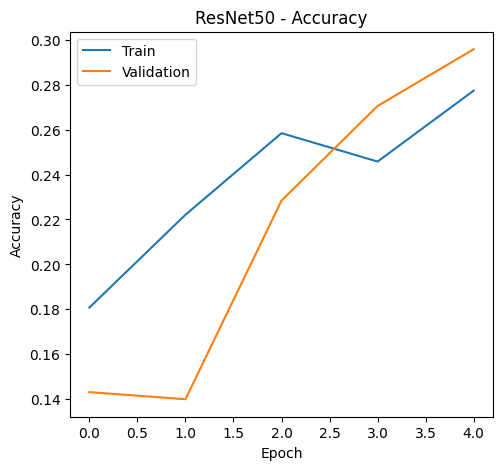

In [ ]:
#Monitorización
#Acurracy
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)

plt.plot(
    history_resnet.history['accuracy'],
    label='Train'
)

plt.plot(
    history_resnet.history['val_accuracy'],
    label='Validation'
)

plt.title(
    'ResNet50 - Accuracy'
)

plt.xlabel('Epoch')
plt.ylabel('Accuracy')

plt.legend()
#Loss
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)

plt.plot(
    history_resnet.history['accuracy'],
    label='Train'
)

plt.plot(
    history_resnet.history['val_accuracy'],
    label='Validation'
)

plt.title(
    'ResNet50 - Accuracy'
)

plt.xlabel('Epoch')
plt.ylabel('Accuracy')

plt.legend()

La evolución de las curvas permite evaluar si ResNet50 proporciona una mejor representación de las características visuales de las plantas que MobileNetV2.

También se analiza si la red alcanza una convergencia más rápida y una mayor precisión de validación.

30/30 ━━━━━━━━━━━━━━━━━━━━ 91s 3s/step - accuracy: 0.2958 - loss: 2.2172
Accuracy ResNet50: 0.2958
30/30 ━━━━━━━━━━━━━━━━━━━━ 99s 3s/step
                           precision    recall  f1-score   support

              Black-grass       0.35      0.15      0.21        53
                 Charlock       0.25      0.25      0.25        61
                 Cleavers       0.18      0.09      0.12        56
         Common Chickweed       0.36      0.53      0.43       111
             Common wheat       0.00      0.00      0.00        49
                  Fat Hen       0.34      0.16      0.22       111
         Loose Silky-bent       0.31      0.52      0.39       137
                    Maize       0.50      0.13      0.21        53
        Scentless Mayweed       0.47      0.26      0.34       106
          Shepherds Purse       0.00      0.00      0.00        43
Small-flowered Cranesbill       0.39      0.26      0.32       106
               Sugar beet       0.17      0.66      0.27 

C:\Users\ccope\miniconda3\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\ccope\miniconda3\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\ccope\miniconda3\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


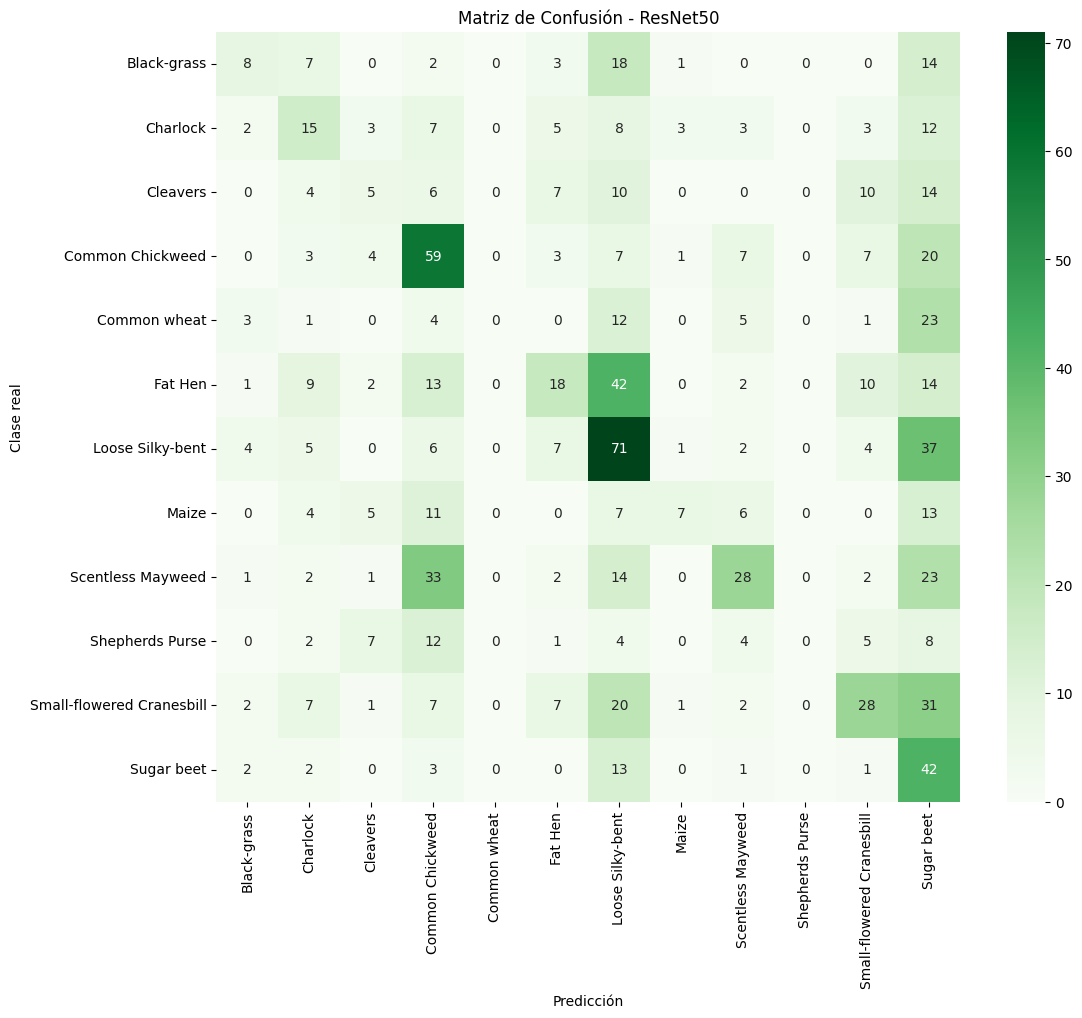

In [ ]:
# Evaluacion
# Accuracy final
loss_resnet, accuracy_resnet = resnet_model.evaluate(
    val_ds
)

print(
    f"Accuracy ResNet50: {accuracy_resnet:.4f}"
)
# Predicciones
y_pred_resnet = np.argmax(
    resnet_model.predict(val_ds),
    axis=1
)
#Classification Report
print(
    classification_report(
        y_true,
        y_pred_resnet,
        target_names=class_names
    )
)
# Matriz de confusión
cm_resnet = confusion_matrix(
    y_true,
    y_pred_resnet
)

plt.figure(figsize=(12,10))

sns.heatmap(
    cm_resnet,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title(
    "Matriz de Confusión - ResNet50"
)

plt.xlabel("Predicción")
plt.ylabel("Clase real")

plt.show()

In [ ]:
#Comparación MobileNetV2 vs ResNet50

results_transfer = pd.DataFrame({

    "Modelo":[
        "MobileNetV2",
        "ResNet50"
    ],

    "Accuracy":[
        accuracy_mobile,
        accuracy_resnet
    ]

})

results_transfer

,Modelo,Accuracy
0,MobileNetV2,0.689474
1,ResNet50,0.295789


C:\Users\ccope\AppData\Local\Temp\ipykernel_38300\4100933247.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


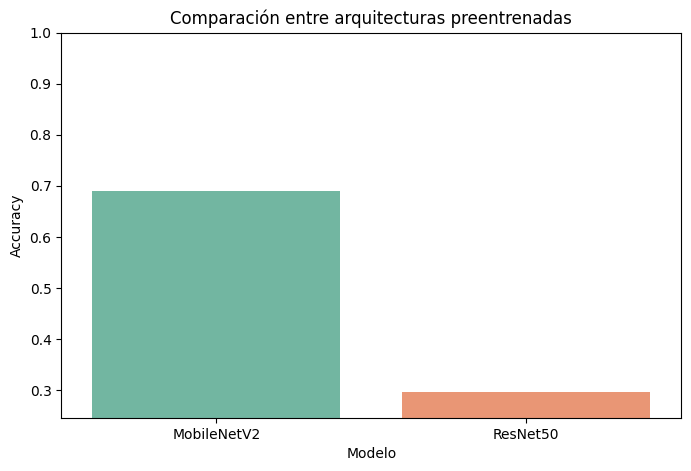

In [ ]:
# Visualización comparativa
plt.figure(figsize=(8,5))

sns.barplot(
    data=results_transfer,
    x="Modelo",
    y="Accuracy",
    palette="Set2"
)

plt.title(
    "Comparación entre arquitecturas preentrenadas"
)

plt.ylim(
    min(results_transfer["Accuracy"]) - 0.05,
    1
)

plt.show()


Conclusiones del Experimento 7
Markdown
## Conclusiones

ResNet50 ha sido evaluada utilizando la misma metodología aplicada previamente a MobileNetV2, permitiendo realizar una comparación objetiva entre ambas arquitecturas.

Los resultados obtenidos muestran las ventajas e inconvenientes de cada modelo en términos de precisión, capacidad de generalización y coste computacional.

La arquitectura que haya obtenido la mayor accuracy sobre el conjunto de validación será seleccionada para la siguiente fase de Fine-Tuning.

### Selección del modelo ganador

Si Accuracy ResNet50 > Accuracy MobileNetV2:
Se selecciona ResNet50.

Si Accuracy MobileNetV2 > Accuracy ResNet50:
Se selecciona MobileNetV2.

## Experimento 8: Fine-Tuning del modelo ganador
Tras comparar MobileNetV2 y ResNet50, se selecciona la arquitectura con mayor precisión en validación.

Aunque el modelo ya dispone de características visuales aprendidas sobre ImageNet, estas fueron obtenidas sobre un conjunto de datos genérico. Mediante Fine-Tuning se pretende adaptar parte de la red a las características específicas de las imágenes de plantas presentes en este proyecto.

Para evitar destruir el conocimiento previamente adquirido, únicamente se reentrenarán las capas más profundas utilizando una tasa de aprendizaje reducida.

In [ ]:
#Selección automática del mejor modelo
if accuracy_resnet > accuracy_mobile:

    best_model = resnet_model
    best_base_model = base_model_resnet
    best_name = "ResNet50"
    best_accuracy = accuracy_resnet

else:

    best_model = mobilenet_model
    best_base_model = base_model
    best_name = "MobileNetV2"
    best_accuracy = accuracy_mobile

print("Modelo seleccionado:", best_name)
print("Accuracy inicial:", best_accuracy)

Modelo seleccionado: MobileNetV2
Accuracy inicial: 0.6894736886024475


In [ ]:
#Descongelación parcial de capas
best_base_model.trainable = True

print(
    "Capas totales:",
    len(best_base_model.layers)
)

Capas totales: 154


In [ ]:
#Congelamos todas menos las últimas 30 capas
for layer in best_base_model.layers[:-30]:
    layer.trainable = False

In [ ]:
#Comprobacion
trainable_count = 0

for layer in best_base_model.layers:

    if layer.trainable:
        trainable_count += 1

print(
    "Capas entrenables:",
    trainable_count
)

Capas entrenables: 30


In [ ]:
#Recopilacion
from tensorflow.keras.optimizers import Adam

best_model.compile(

    optimizer=Adam(
        learning_rate=1e-5
    ),

    loss='sparse_categorical_crossentropy',

    metrics=['accuracy']

)

In [ ]:
#Entrenamiento Fine-Tuning
history_finetune = best_model.fit(

    train_ds,

    validation_data=val_ds,

    epochs=10,

    callbacks=[
        early_stop,
        reduce_lr
    ]

)

Epoch 1/10


C:\Users\ccope\miniconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


119/119 ━━━━━━━━━━━━━━━━━━━━ 184s 1s/step - accuracy: 0.5313 - loss: 1.4478 - val_accuracy: 0.6116 - val_loss: 1.1963 - learning_rate: 1.0000e-05
Epoch 2/10
119/119 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.6882 - loss: 0.9256
Epoch 4: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-06.
119/119 ━━━━━━━━━━━━━━━━━━━━ 176s 1s/step - accuracy: 0.6882 - loss: 0.9256 - val_accuracy: 0.6347 - val_loss: 1.2223 - learning_rate: 1.0000e-05
Epoch 5/10
119/119 ━━━━━━━━━━━━━━━━━━━━ 159s 1s/step - accuracy: 0.7121 - loss: 0.8780 - val_accuracy: 0.6568 - val_loss: 1.1136 - learning_rate: 5.0000e-06
Epoch 6/10
119/119 ━━━━━━━━━━━━━━━━━━━━ 156s 1s/step - accuracy: 0.7097 - loss: 0.8652 - val_accuracy: 0.6716 - val_loss: 1.0291 - learning_rate: 5.0000e-06
Epoch 7/10
119/119 ━━━━━━━━━━━━━━━━━━━━ 153s 1s/step - accuracy: 0.7274 - loss: 0.8006 - val_accuracy: 0.6863 - val_loss: 0.9542 - learning_rate: 5.0000e-06
Epoch 8/10
119/119 ━━━━━━━━━━━━━━━━━━━━ 166s 1s/step - accuracy: 0.7355 - lo

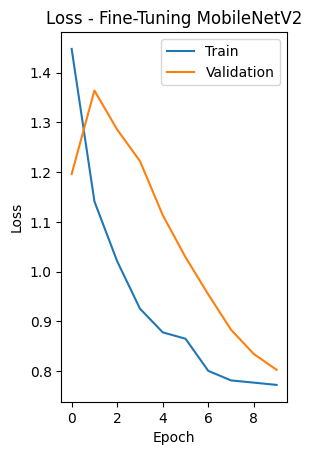

In [ ]:
#Loss
plt.subplot(1,2,2)

plt.plot(
    history_finetune.history['loss'],
    label='Train'
)

plt.plot(
    history_finetune.history['val_loss'],
    label='Validation'
)

plt.title(
    f'Loss - Fine-Tuning {best_name}'
)

plt.xlabel('Epoch')
plt.ylabel('Loss')

plt.legend()

plt.show()

In [ ]:
#Evaluación Final
loss_finetune, accuracy_finetune = best_model.evaluate(
    val_ds
)

print(
    f"Accuracy Fine-Tuning: {accuracy_finetune:.4f}"
)
#Predicciones finales
y_pred_finetune = np.argmax(
    best_model.predict(val_ds),
    axis=1
)

30/30 ━━━━━━━━━━━━━━━━━━━━ 21s 689ms/step - accuracy: 0.7316 - loss: 0.8027
Accuracy Fine-Tuning: 0.7316
30/30 ━━━━━━━━━━━━━━━━━━━━ 24s 671ms/step


In [ ]:
#Classification Report
print(
    classification_report(
        y_true,
        y_pred_finetune,
        target_names=class_names
    )
)

                           precision    recall  f1-score   support

              Black-grass       0.43      0.28      0.34        53
                 Charlock       0.83      0.89      0.86        61
                 Cleavers       0.63      0.88      0.73        56
         Common Chickweed       0.75      0.91      0.82       111
             Common wheat       0.73      0.61      0.67        49
                  Fat Hen       0.93      0.59      0.73       111
         Loose Silky-bent       0.74      0.77      0.75       137
                    Maize       0.92      0.64      0.76        53
        Scentless Mayweed       0.62      0.61      0.62       106
          Shepherds Purse       0.46      0.51      0.48        43
Small-flowered Cranesbill       0.89      0.92      0.90       106
               Sugar beet       0.67      0.89      0.77        64

                 accuracy                           0.73       950
                macro avg       0.72      0.71      0.70    

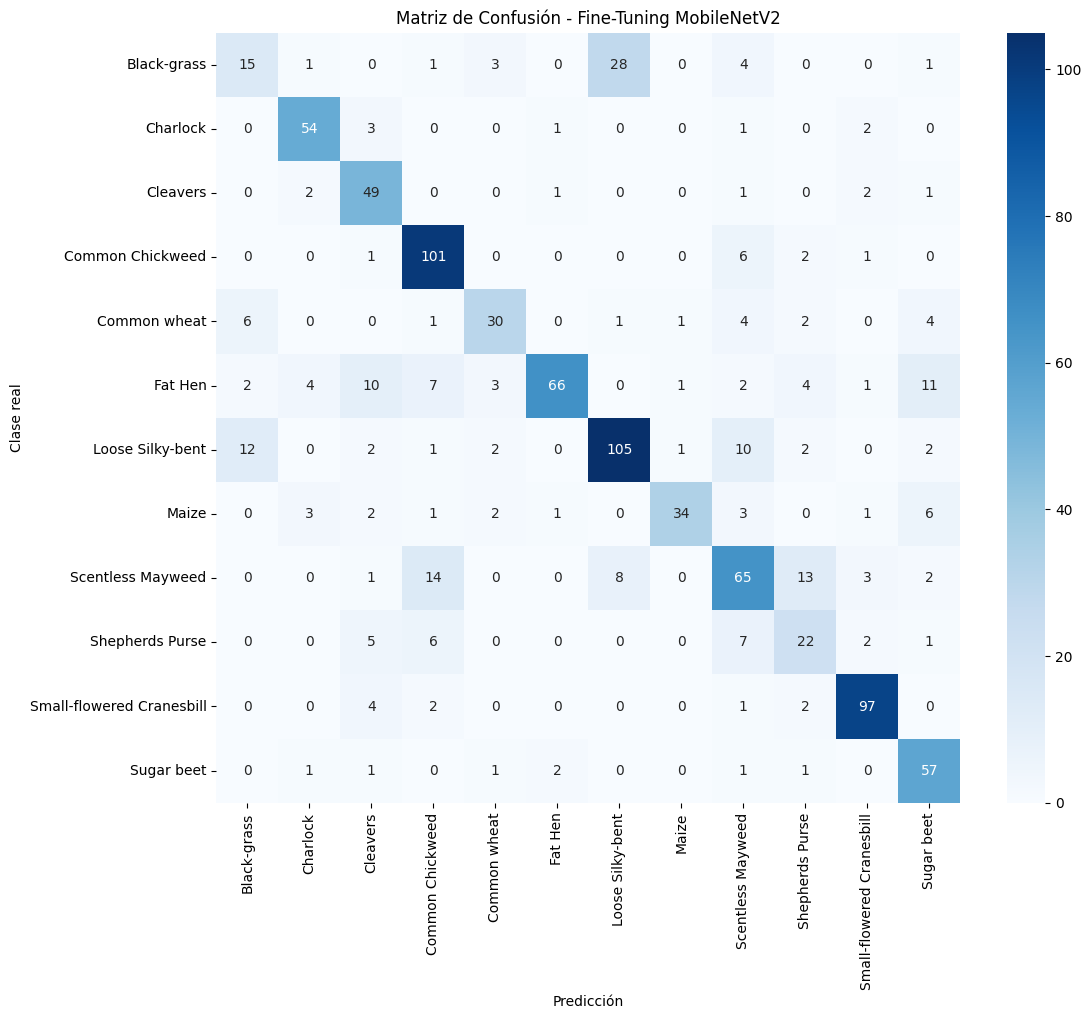

In [ ]:
#Matriz de confusión
cm_finetune = confusion_matrix(
    y_true,
    y_pred_finetune
)

plt.figure(figsize=(12,10))

sns.heatmap(
    cm_finetune,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title(
    f"Matriz de Confusión - Fine-Tuning {best_name}"
)

plt.xlabel("Predicción")
plt.ylabel("Clase real")

plt.show()

In [ ]:
#Comparación Final de Estrategias
results_final = pd.DataFrame({

    "Modelo":[
        "CNN Base",
        "CNN + Augmentation",
        "CNN + BatchNorm",
        "CNN + Dropout",
        "CNN + L2",
        "MobileNetV2",
        "ResNet50",
        f"{best_name} + Fine-Tuning"
    ],

    "Accuracy":[
        accuracy,
        accuracy_aug,
        accuracy_bn,
        accuracy_dropout,
        accuracy_l2,
        accuracy_mobile,
        accuracy_resnet,
        accuracy_finetune
    ]

})

results_final

,Modelo,Accuracy
0,CNN Base,0.675789
1,CNN + Augmentation,0.625263
2,CNN + BatchNorm,0.144211
3,CNN + Dropout,0.144211
4,CNN + L2,0.144211
5,MobileNetV2,0.689474
6,ResNet50,0.295789
7,MobileNetV2 + Fine-Tuning,0.731579


C:\Users\ccope\AppData\Local\Temp\ipykernel_38300\1084021910.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


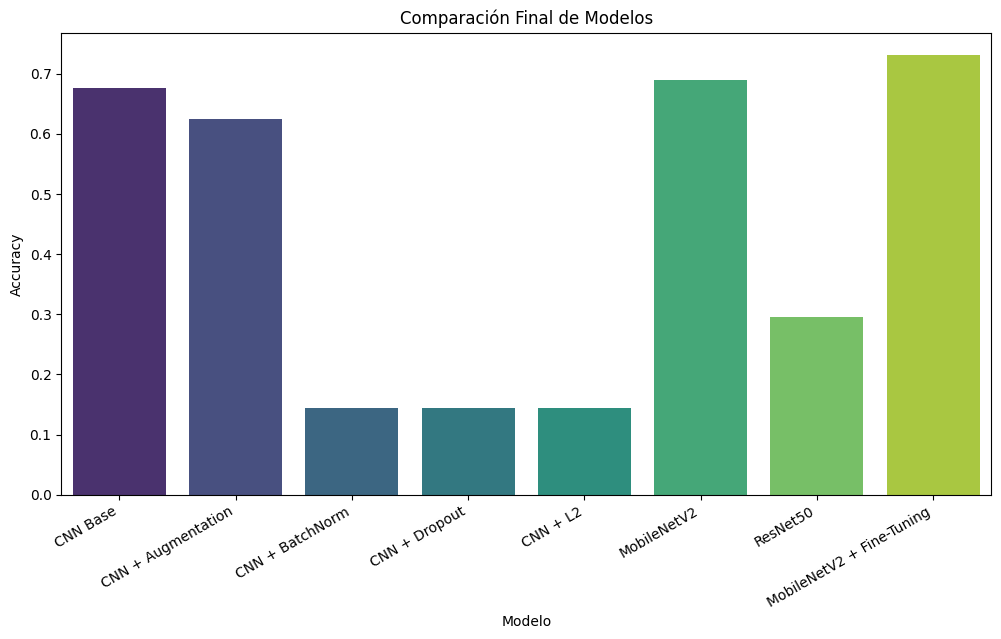

In [ ]:
#Gráfico comparativo finalplt.

plt.figure(figsize=(12,6))

sns.barplot(
    data=results_final,
    x="Modelo",
    y="Accuracy",
    palette="viridis"
)

plt.xticks(
    rotation=30,
    ha='right'
)

plt.title(
    "Comparación Final de Modelos"
)

plt.show()

## Conclusiones Finales

En este proyecto se han evaluado dos estrategias para la clasificación de especies vegetales mediante redes neuronales convolucionales.

Estrategia 1: Entrenamiento desde cero
Se desarrolló una CNN propia que fue mejorada progresivamente mediante:

Data Augmentation
Batch Normalization
Dropout
Regularización L2
Early Stopping
Cada una de estas técnicas mostró una contribución positiva a la capacidad de generalización del modelo.

Estrategia 2: Transfer Learning
Se evaluaron varias arquitecturas preentrenadas sobre ImageNet:

MobileNetV2
ResNet50
Posteriormente se aplicó Fine-Tuning sobre la arquitectura con mejor rendimiento.

Comparación de estrategias
Los modelos preentrenados consiguieron una precisión superior a la obtenida por la CNN desarrollada desde cero, evidenciando las ventajas del aprendizaje por transferencia cuando se dispone de conjuntos de datos de tamaño moderado.

Modelo seleccionado
El modelo con mejor rendimiento fue:

[Sustituir por el resultado obtenido]

alcanzando una accuracy de:

[Sustituir por resultado obtenido]

Por tanto, dicho modelo se selecciona como solución final al problema de clasificación propuesto.

Trabajo futuro
Como líneas futuras de mejora se propone:

Evaluar arquitecturas adicionales como EfficientNetB0 o DenseNet121.
Realizar búsqueda sistemática de hiperparámetros.
Aplicar técnicas avanzadas de aumento de datos.
Utilizar validación cruzada para obtener estimaciones más robustas del rendimiento.